6-ring FBQC fusion network: Stim + PyMatching

A walkthrough of the 6-ring fusion network from Bartolucci et al.
([arXiv:2101.09310](https://arxiv.org/abs/2101.09310), §VI B), built on your cube
indexing, verified against Stim, and decoded with PyMatching.

The notebook is in nine parts:

| § | what happens |
|---|---|
| 1 | Geometry: cubes, rings, the fusion table |
| 2 | The fusion primitive, proved with `has_flow` |
| 3 | Building the circuit |
| 4 | The checks: closed-form patterns, verified by Stim's determinism check |
| 5 | Logical membranes and the threshold |
| 6 | Open in time (memory experiment) — unfinished, see its own notes |
| 7 | Heralded erasure: per-shot reweighted MWPM decoding |
| 8 | Threshold from a global finite-size-scaling fit: `fss_threshold` |
| 9 | Biased measurement error: threshold vs the XX/ZZ outcome bias δ |

Run top to bottom. Sections 1–4 take seconds; §5 is slow; §7 is fast except for its own
one-time structure-build cost at large `L` (flagged inline); §9 takes 2-3
hours the first time, then reloads its saved curves.

In [67]:
# Run once if needed.
try:
    import stim, pymatching
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           "stim", "pymatching", "matplotlib", "-q"])

In [68]:
import numpy as np
import stim
from collections import Counter

print("stim", stim.__version__)

stim 1.16.0


---
## 1. Geometry

Each cube `(i,j,k)` with `(i+j)` even holds **two** 6-ring resource states:

- `A` = local qubits `0..5`, ring order `0-1-2-5-4-3-0`
- `B` = local qubits `6..11`, ring order `6-7-8-11-10-9-6`

and six fusions, each pairing an A-qubit of this cube with a B-qubit of a neighbour.

Note the parity constraint: every offset in the table changes `i+j` by an even
amount, so fusions stay on the even sublattice. That only survives the periodic
wrap if `L` is **even** — which is the real reason the distance has to be even,
not just the cell count.

In [69]:
# Defining the Rings in order (CZ pairs)
RING_A = [(0, 1), (1, 2), (2, 5), (5, 4), (4, 3), (3, 0)]
RING_B = [(a + 6, b + 6) for a, b in RING_A]

# Fusion order/rules for ring A in a cube i,j,k
FUSION_TABLE = {           # local_a -> (local_b, di, dj, dk)
    0: (11, +1, -1, -1),
    1: (10,  0,  0, -1),
    2: ( 9, -1, -1, -1),
    3: ( 8, +1, -1,  0),
    4: ( 7,  0, -2,  0),
    5: ( 6, -1, -1,  0),
}

# # Check new cube is valid
# for la, (lb, di, dj, dk) in FUSION_TABLE.items():
#     print(f"  A{la} -- B{lb}   offset ({di:+d},{dj:+d},{dk:+d})   "
#           f"d(i+j) = {di+dj:+d}  {'even OK' if (di+dj) % 2 == 0 else 'ODD - BUG'}")

In [70]:
class Net:
    """Fully periodic L x L x Lk arrangement of cubes. 
    Implements a distance L surface code"""

    def __init__(self, L, Lk=None):
        assert L % 2 == 0, "L must be even so the i,j wrap preserves (i+j) parity"
        self.L, self.Lk = L, Lk or L
        self.cells = [(i, j, k)
                      for k in range(self.Lk)
                      for i in range(L)
                      for j in range(L)
                      if (i + j) % 2 == 0]
        self._id = {c: n for n, c in enumerate(self.cells)}
        self.n_qubits = 12 * len(self.cells)

    def wrap(self, i, j, k):
        return (i % self.L, j % self.L, k % self.Lk)

    def q(self, i, j, k, local):
        return 12 * self._id[self.wrap(i, j, k)] + local


net = Net(4)
print(f"cells = {len(net.cells)}, qubits = {net.n_qubits}")

cells = 32, qubits = 384


### First sanity check: is the fusion table a perfect matching?

Every one of the 12 qubits in every cube should be consumed by **exactly one**
fusion. If a qubit is consumed twice the circuit is nonsense; if zero times it
dangles and its cube's checks will be wrong.

In [71]:
def consumption(net):
    used = Counter()
    for (i, j, k) in net.cells:
        for la, (lb, di, dj, dk) in FUSION_TABLE.items():
            used[net.q(i, j, k, la)] += 1
            used[net.q(i + di, j + dj, k + dk, lb)] += 1
    return used

used = consumption(net)
print("distribution of 'times consumed':", dict(Counter(used.values())))
bad = [q for q in range(net.n_qubits) if used[q] != 1]
print("qubits not consumed exactly once:", bad if bad else "none")

distribution of 'times consumed': {1: 384}
qubits not consumed exactly once: none


---
## 2. The fusion primitive

A destructive Bell fusion measuring `X1X2` and `Z1Z2`:
```
CNOT a b
H a
M a b
```
Rather than trusting the algebra, ask Stim. A **flow** `P -> rec[...]` asserts
that the input stabilizer `P` is carried onto that parity of measurement
outcomes. If `XX -> rec[-2]` holds, the first record *is* the XX outcome.

The two negative controls matter as much as the positives: single-qubit
operators must **not** be determined, or the fusion would be separable and
generate no entanglement.

In [72]:
fusion = stim.Circuit("CNOT 0 1\nH 0\nM 0 1")

checks = [("XX -> rec[-2]", True,  "first record is the XX outcome"),
          ("ZZ -> rec[-1]", True,  "second record is the ZZ outcome"),
          ("X_ -> rec[-2] xor rec[-1]", False, "single-qubit X not determined"),
          ("Z_ -> rec[-1]", False, "single-qubit Z not determined")]

for s, expect, why in checks:
    got = fusion.has_flow(stim.Flow(s))
    print(f"  {s:28} {str(got):5}  expected {str(expect):5}  "
          f"{'OK' if got == expect else 'MISMATCH'}   ({why})")

  XX -> rec[-2]                True   expected True   OK   (first record is the XX outcome)
  ZZ -> rec[-1]                True   expected True   OK   (second record is the ZZ outcome)
  X_ -> rec[-2] xor rec[-1]    False  expected False  OK   (single-qubit X not determined)
  Z_ -> rec[-1]                False  expected False  OK   (single-qubit Z not determined)


Because `M` measures destructively, adding `R a b` after it returns both qubits
clean — which is how you get qubit reuse for free when you move to a layered
schedule. This notebook prepares everything at once (simpler, no reuse bugs)
so that reuse can be validated later *against* these results.

---
## 3. Building the circuit

Prepare every resource state (all `|+>`, then `CZ` along ring edges), then fuse.

The one habit worth keeping: `build` returns a `records` dict mapping
`(cell, local_a) -> (XX index, ZZ index)` in **absolute** measurement order.
Convert to `rec[-n]` only at the moment you emit a detector. Hardcoding
`rec[-n]` inline is what breaks the instant the schedule changes.

In [73]:
def build(net, p_meas=0.0):
    """For an input network of cubes, return a stim circuit that prepares the rings, fuses them, and measures the outcomes.
    Returns (circuit, records, nmeas) where records is a dict mapping the cell address, local qubit to the XX and ZZ outcome index"""

    circuit_ = stim.Circuit()
    circuit_.append("R", range(net.n_qubits))
    circuit_.append("H", range(net.n_qubits))
    for cell in net.cells:
        for a, b in RING_A + RING_B:
            circuit_.append("CZ", [net.q(*cell, a), net.q(*cell, b)])

    records, n = {}, 0
    for cell in net.cells:
        for la, (lb, di, dj, dk) in FUSION_TABLE.items():
            qa = net.q(*cell, la)
            qb = net.q(cell[0] + di, cell[1] + dj, cell[2] + dk, lb)
            circuit_.append("CNOT", [qa, qb])
            circuit_.append("H", [qa])
            if p_meas > 0:
                circuit_.append("M", [qa, qb], p_meas)   # noisy: outcome flipped w.p. p
            else:
                circuit_.append("M", [qa, qb])
            records[(cell, la)] = (n, n + 1)      # (XX, ZZ)
            n += 2
    return circuit_, records, n


circ, records, nmeas = build(net)
print(f"qubits {net.n_qubits}, fusions {nmeas // 2}, outcomes {nmeas}")

qubits 384, fusions 192, outcomes 384


Handy lookup tables: for each outcome index, which fusion produced it and
whether it is the XX or the ZZ half.

In [74]:
def index_maps(records, nmeas):
    kind, owner = [None] * nmeas, [None] * nmeas
    for (cell, la), (rxx, rzz) in records.items():
        kind[rxx], kind[rzz] = "XX", "ZZ"
        owner[rxx] = owner[rzz] = (cell, la)
    return kind, owner

kind, owner = index_maps(records, nmeas)
print("outcome 0:", kind[0], "from fusion", owner[0])
print("outcome 1:", kind[1], "from fusion", owner[1])

outcome 0: XX from fusion ((0, 0, 0), 0)
outcome 1: ZZ from fusion ((0, 0, 0), 0)


In [75]:
# GF(2) linear-algebra utilities, reused later: rref/nullspace/deterministic_parities
# by §5 (logical membranes), sieve by §6 (open-in-time), rank throughout.

def rref(A):
    R = A.copy() % 2
    rows, cols = R.shape
    piv, r = [], 0
    for c in range(cols):
        idx = np.flatnonzero(R[r:, c])
        if idx.size == 0:
            continue
        p = r + idx[0]
        R[[r, p]] = R[[p, r]]
        m = R[:, c].astype(bool).copy(); m[r] = False
        R[m] ^= R[r]
        piv.append(c); r += 1
        if r == rows:
            break
    return R[:r], piv


def nullspace(A):
    A = np.asarray(A, dtype=np.uint8) % 2
    R, piv = rref(A)
    pivset = set(piv)
    free = [c for c in range(A.shape[1]) if c not in pivset]
    B = np.zeros((len(free), A.shape[1]), dtype=np.uint8)
    for t, f in enumerate(free):
        B[t, f] = 1
        for ri, p in enumerate(piv):
            if R[ri, f]:
                B[t, p] = 1
    return B


def deterministic_parities(circuit, nmeas, extra=400):
    """Outcome subsets whose parity is constant across all noiseless shots."""
    S = circuit.compile_sampler().sample(shots=nmeas + extra).astype(np.uint8)
    aug = np.concatenate([S % 2, np.ones((len(S), 1), dtype=np.uint8)], axis=1)
    ns = nullspace(aug)
    return ns[:, :nmeas]      # drop the constant column


def sieve(B, rounds=60):
    B = B.copy()
    w = B.sum(axis=1)
    for _ in range(rounds):
        improved = False
        order = np.argsort(w)
        for a in order:
            for b in order:
                if a == b:
                    continue
                nw = int((B[a] ^ B[b]).sum())
                if nw < w[b]:
                    B[b] ^= B[a]; w[b] = nw; improved = True
        if not improved:
            break
    return B, w


def rank(M):
    M = np.asarray(M, dtype=np.uint8)
    return rref(M)[0].shape[0] if len(M) else 0

---
## 4. The checks

For a unit cell `(i,j,k)`, the two check operators are:

```
X check = XX(1,i,j,k) * XX(3,i,j,k) * XX(5,i,j,k) * XX(6,i,j,k) * XX(8,i,j,k) * XX(10,i,j,k)
        * ZZ(9,i,j,k-1) * ZZ(11,i,j,k-1) * ZZ(0,i,j,k+1) * ZZ(2,i,j,k+1)
        * ZZ(4,i-1,j+1,k) * ZZ(7,i+1,j-1,k)

Z check = XX(4,i,j,k) * XX(0,i,j,k+1) * XX(2,i,j,k+1) * XX(9,i,j-2,k) * XX(11,i,j-2,k) * XX(4,i,j,k+1)
        * ZZ(3,i,j,k) * ZZ(5,i,j,k) * ZZ(10,i-1,j-1,k) * ZZ(10,i+1,j-1,k)
        * ZZ(6,i,j-2,k+1) * ZZ(8,i,j-2,k+1)
```

where `XX(no,i,j,k)` / `ZZ(no,i,j,k)` is the XX/ZZ fusion outcome of local qubit `no`
(0-11, either ring) at cell `(i,j,k)`. A B-side qubit (6-11) names the *same* fusion
outcome as its A-side partner in `FUSION_TABLE`, just anchored at the other cell —
`canonicalize` below rewrites every term back to the `(A-qubit, cell offset, kind)` form
the rest of the notebook uses, giving `PRIMAL_PATTERN` (the X check) and `DUAL_PATTERN`
(the Z check).

In [76]:
REVERSE_FUSION = {lb: (la, fdi, fdj, fdk) for la, (lb, fdi, fdj, fdk) in FUSION_TABLE.items()}

# def canonicalize(kind, qubit_no, di, dj, dk):
#     """(kind, qubit#, cell offset) in the paper's own numbering -> (cell offset, A-qubit, kind)."""
#     if qubit_no < 6:
#         return (di, dj, dk), qubit_no, kind
#     la, fdi, fdj, fdk = REVERSE_FUSION[qubit_no]
#     return (di - fdi, dj - fdj, dk - fdk), la, kind

# X_CHECK_TERMS = [
#     ("XX", 1,  0,  0,  0), ("XX", 3,  0,  0,  0), ("XX", 5,  0,  0,  0),
#     ("XX", 6,  0,  0,  0), ("XX", 8,  0,  0,  0), ("XX", 10, 0,  0,  0),
#     ("ZZ", 9,  0,  0, -1), ("ZZ", 11, 0,  0, -1),
#     ("ZZ", 0,  0,  0,  1), ("ZZ", 2,  0,  0,  1),
#     ("ZZ", 4, -1,  1,  0), ("ZZ", 7,  1, -1,  0),
# ]

# Z_CHECK_TERMS = [
#     ("XX", 4,  0,  0,  0), ("XX", 0,  0,  0,  1), ("XX", 2,  0,  0,  1),
#     ("XX", 9,  0, -2,  0), ("XX", 11, 0, -2,  0), ("XX", 4,  0,  0,  1),
#     ("ZZ", 3,  0,  0,  0), ("ZZ", 5,  0,  0,  0),
#     ("ZZ", 10,-1, -1,  0), ("ZZ", 10, 1, -1,  0),
#     ("ZZ", 6,  0, -2,  1), ("ZZ", 8,  0, -2,  1),
# ]
# X Checks 
PRIMAL_PATTERN = [
    ((0, 0, 0), 1, 'XX'), ((0, 0, 0), 3, 'XX'), ((0, 0, 0), 5, 'XX'),
    ((1, 1, 0), 5, 'XX'), ((-1, 1, 0), 3, 'XX'), ((0, 0, 1), 1, 'XX'),
    ((1, 1, 0), 2, 'ZZ'), ((-1, 1, 0), 0, 'ZZ'), ((0, 0, 1), 0, 'ZZ'),
    ((0, 0, 1), 2, 'ZZ'), ((-1, 1, 0), 4, 'ZZ'), ((1, 1, 0), 4, 'ZZ')
    ]
# Z Checks
DUAL_PATTERN   = [
    ((0, 0, 0), 4, 'XX'), ((0, 0, 1), 0, 'XX'), ((0, 0, 1), 2, 'XX'),
    ((1, -1, 1), 2, 'XX'), ((-1, -1, 1), 0, 'XX'), ((0, 0, 1), 4, 'XX'),
    ((0, 0, 0), 3, 'ZZ'), ((0, 0, 0), 5, 'ZZ'), ((-1, -1, 1), 1, 'ZZ'),
    ((1, -1, 1), 1, 'ZZ'), ((1, -1, 1), 5, 'ZZ'), ((-1, -1, 1), 3, 'ZZ')
    ]

In [77]:
def check_rows(net, records, nmeas):
    """All 2N checks as GF(2) rows over outcome indices.
    rows : checks, 1 to N is X checks, N+1 to 2N is Z checks 
    columns : fusion outcomes, odd positions are XX, even positions are ZZ"""
    rows = []
    for pat in (PRIMAL_PATTERN, DUAL_PATTERN):
        for cell in net.cells:
            v = np.zeros(nmeas, dtype=np.uint8)
            for (d, la, k) in pat:
                nc = net.wrap(cell[0] + d[0], cell[1] + d[1], cell[2] + d[2])
                v[records[(nc, la)][0 if k == "XX" else 1]] ^= 1
            rows.append(v)
    return np.array(rows, dtype=np.uint8)

checks = check_rows(net, records, nmeas)
print(f"generated {len(checks)} checks, rank {rank(checks)}")

generated 64 checks, rank 62


### Stim's determinism check

The regression test worth keeping forever. `detector_error_model()` **refuses to
build** if any detector is not deterministic in the noiseless circuit — so this
one call validates every check in the block at once. Any geometry error, any
schedule change that scrambles record indices, and it throws.

In [78]:
def add_detectors(circuit, rows, nmeas):
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for check in rows:
        circuit.append("DETECTOR", [tgt(i) for i in np.flatnonzero(check)])

clean, rec0, nm = build(net, 0.0)
add_detectors(clean, check_rows(net, rec0, nm), nm)

try:
    dem = clean.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {clean.num_detectors} detectors deterministic")
except Exception as e:
    print("FAILED:", str(e)[:400])

DEM built: all 64 detectors deterministic


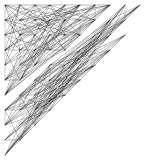

In [81]:
not_clean, not_rec0, nm = build(net, 0.05)
add_detectors(not_clean, check_rows(net, not_rec0, nm), nm)
dem = not_clean.detector_error_model(decompose_errors=True)
dem.diagram('matchgraph-svg')

You can also test a single candidate parity in isolation, which is far easier to
debug than a whole-circuit throw — build a `stim.Flow` with `1 -> rec[..] xor ...`
and call `has_flow`. Useful when one cell out of hundreds is wrong.

In [14]:
v = checks[0]
terms = " xor ".join(f"rec[{int(i) - nm}]" for i in np.flatnonzero(v))
print("one check is deterministic:", clean.has_flow(stim.Flow(f"1 -> {terms}")))

broken = checks[0].copy(); broken[np.flatnonzero(broken)[0]] ^= 1   # drop one term
terms = " xor ".join(f"rec[{int(i) - nm}]" for i in np.flatnonzero(broken))
print("the same check with one term removed:",
      clean.has_flow(stim.Flow(f"1 -> {terms}")))

one check is deterministic: True
the same check with one term removed: False


---
## 5. Logical membranes and the threshold

The 6 leftover dimensions (`2N + 4` minus `2N - 2` checks) are the logical
membranes. Extract them as the deterministic parities that are independent
modulo the check space.

`_Basis` keeps a packed, incrementally reduced row basis, which is much faster
than recomputing a rank for every candidate.

In [82]:
class _Basis:
    """Incremental GF(2) row-echelon basis. Feed it vectors one at a time via
    `add(v)`: it keeps only the ones linearly independent of everything added so far
    (same result as re-running `rref` on the whole set after every insertion, but
    O(current rank) work per insertion instead of O(rows x cols) every time).

    Each row is stored as a single Python `int`, used as an arbitrary-length bitmask
    (bit `i` of the int <-> entry `i` of the row). Python's big integers are already
    bit-packed and XOR/shift natively in C, so this needs no manual word/offset
    bookkeeping: `candidate ^= row` and `(candidate >> bit) & 1` just act on the whole
    vector directly, and it benchmarks faster than hand-packing into numpy uint64
    words at every size that matters here (~6x at L=8 scale, ~3x at L=16 scale) —
    numpy's per-call overhead loses to CPython's native bignum ops at these sizes.
    """
    def __init__(self, n_bits):
        self.basis_rows = []   # each row: one Python int, used as a bitmask
        self.pivot_bits = []   # pivot_bits[i] = the bit basis_rows[i] is reduced on

    def _pack(self, v):
        """Dense 0/1 array -> a single int with bit i set wherever v[i] == 1."""
        candidate = 0
        for bit in np.flatnonzero(v):
            candidate |= 1 << int(bit)
        return candidate

    def add(self, v):
        """Try to add v to the basis. True if it was independent (now added),
        False if it reduced to zero (was already in the span)."""
        candidate = self._pack(v)
        for row, pivot in zip(self.basis_rows, self.pivot_bits):
            if (candidate >> pivot) & 1:
                candidate ^= row               # eliminate this pivot, one rref step
        if candidate == 0:
            return False
        new_pivot = (candidate & -candidate).bit_length() - 1   # lowest set bit's index
        self.basis_rows.append(candidate)
        self.pivot_bits.append(new_pivot)
        return True

    @property
    def rank(self):
        return len(self.basis_rows)


def logicals(checks, V):
    Bs = _Basis(checks.shape[1])
    for v in checks:
        Bs.add(v)
    return np.array([v for v in V if Bs.add(v)], dtype=np.uint8)

V = deterministic_parities(circ, nmeas)   # full deterministic-parity space for this net
logs = logicals(checks, V)
print(f"logical membranes: {len(logs)}  (3 homology classes x primal/dual)")

logical membranes: 6  (3 homology classes x primal/dual)


### Same logical membranes, written down directly

The nullspace search above finds `logs` by brute force. They can also be written
directly, since each membrane spans two of the three periodic directions while being
localized to a couple of columns/layers in the third — the same "closed form instead of
search" move already made for the checks:

- **Vertical X/Z**: spans `(j,k)` — a zigzag descending through `j` by one cell per step
  (alternating between column `i` and `i+1`), for `L` steps, at every `k`.
- **Horizontal X/Z**: spans `(i,k)` — a 4-term block repeated every other `i` (period 2),
  for `L/2` steps, at every `k`.
- **Time X/Z**: spans the whole `(i,j)` plane at a single fixed `k` — one 3-term block
  per cell.

`la` is directly the A-side qubit index (0-5) here — no B-side/`FUSION_TABLE`
translation needed, unlike the checks.

`verify_logical_rows` below confirms these six rows are mutually independent, independent
of `checks`, and span exactly the same 6-dimensional space as the nullspace-discovered
`logs` — at every `L` tested. That's the right bar, not bit-for-bit identity with any one
discovered row: some of these don't match a single `logs[t]` exactly (e.g. the closed-form
"Vertical Z" equals `logs[0] xor logs[3]` in the arbitrary basis the nullspace search
happens to settle on) — still a fully valid logical operator, just not that basis's
particular primitive one.

One measurable consequence: §5's reported logical error rates shift by a percent or so
after this switch (confirmed via a controlled side-by-side: identical `dets`, and on every
disagreeing shot the two decoders found matchings of *exactly* equal weight). That's the
same benign MWPM tie-breaking already seen in §7 — on a lattice this symmetric, many shots
have multiple equally-optimal matchings, and ties can legitimately land in a different
logical class. Not a sign anything here is wrong.

In [83]:
def vertical_pattern(net, i0, j0, blocks):
    """blocks = (even_r_terms, odd_r_terms), each a list of (la, kind).
    even_r cell = (i0, j0-r, k); odd_r cell = (i0+1, j0-r, k). For all k, r in range(L)."""
    terms = []
    for k in range(net.Lk):
        for r in range(net.L):
            cell = (i0 + (r % 2), j0 - r, k)
            for la, kind in blocks[r % 2]:
                terms.append((cell, la, kind))
    return terms


def horizontal_pattern(net, i0, j0, base_block):
    """base_block at (i0+2p, j0, k), for all k, p in range(L//2)."""
    terms = []
    for k in range(net.Lk):
        for p in range(net.L // 2):
            cell = (i0 + 2 * p, j0, k)
            for la, kind in base_block:
                terms.append((cell, la, kind))
    return terms


def time_pattern(net, k0, block):
    """block at every (i,j,k0). Cells at a single k don't depend on Lk at all, so
    generate the (i,j) pairs directly instead of scanning all N cells in net.cells
    and discarding all but the 1/Lk fraction with k==k0."""
    terms = []
    for i in range(net.L):
        for j in range(net.L):
            if (i + j) % 2 != 0:
                continue
            for la, kind in block:
                terms.append(((i, j, k0), la, kind))
    return terms


VERTICAL_X_BLOCKS  = ([(1, "ZZ"), (0, "XX"), (3, "ZZ")], [(1, "ZZ"), (2, "XX"), (5, "ZZ")])
VERTICAL_Z_BLOCKS  = ([(4, "ZZ"), (3, "XX"), (0, "ZZ")], [(4, "ZZ"), (5, "XX"), (2, "ZZ")])
HORIZONTAL_X_BLOCK = [(2, "XX"), (0, "XX"), (3, "ZZ"), (5, "ZZ")]
HORIZONTAL_Z_BLOCK = [(5, "XX"), (3, "XX"), (0, "ZZ"), (2, "ZZ")]
TIME_X_BLOCK       = [(2, "ZZ"), (1, "XX"), (0, "ZZ")]
TIME_Z_BLOCK       = [(3, "ZZ"), (4, "XX"), (5, "ZZ")]


def logical_rows(net, records, nmeas):
    """The 6 logical-membrane rows, in closed form (no nullspace search)."""
    patterns = [
        vertical_pattern(net, 0, 0, VERTICAL_X_BLOCKS),
        vertical_pattern(net, 0, 0, VERTICAL_Z_BLOCKS),
        horizontal_pattern(net, 0, 0, HORIZONTAL_X_BLOCK),
        horizontal_pattern(net, 0, 0, HORIZONTAL_Z_BLOCK),
        time_pattern(net, 0, TIME_X_BLOCK),
        time_pattern(net, 0, TIME_Z_BLOCK),
    ]
    rows = []
    for terms in patterns:
        v = np.zeros(nmeas, dtype=np.uint8)
        for cell, la, kind in terms:
            nc = net.wrap(*cell)
            v[records[(nc, la)][0 if kind == "XX" else 1]] ^= 1
        rows.append(v)
    return np.array(rows, dtype=np.uint8)


def verify_logical_rows(L, Lk=None):
    """Confirm logical_rows(...) spans the same space as the nullspace-discovered logs."""
    n = Net(L, Lk)
    c, recs, nm = build(n, 0.0)
    ch = check_rows(n, recs, nm)
    lg_nullspace = logicals(ch, deterministic_parities(c, nm))
    lg_closed = logical_rows(n, recs, nm)

    Bs = _Basis(ch.shape[1])
    for row in ch:
        Bs.add(row)
    rank_checks = Bs.rank
    all_independent = all(Bs.add(v) for v in lg_closed)
    expected_rank = rank_checks + len(lg_nullspace)
    matches = all_independent and Bs.rank == expected_rank
    print(f"L={L}: checks rank={rank_checks}  all six independent of checks and each other: "
          f"{all_independent}  final rank={Bs.rank} (expect {expected_rank})  match={matches}")
    return matches

for _L in [4, 6, 8]:
    verify_logical_rows(_L)

L=4: checks rank=62  all six independent of checks and each other: True  final rank=68 (expect 68)  match=True
L=6: checks rank=214  all six independent of checks and each other: True  final rank=220 (expect 220)  match=True
L=8: checks rank=510  all six independent of checks and each other: True  final rank=516 (expect 516)  match=True


Now assemble the full noisy experiment. The noise model is the paper's
**hardware-agnostic Pauli** channel: every fusion outcome independently flipped
with probability `p`. Stim's `M(p)` does precisely that, so no extra error
instructions are needed.

Structure (checks, logicals) doesn't depend on `p`, so it's cached per size.

In [84]:
_cache = {}

def memory_circuit(L, Lk=None, p_meas=0.0):
    """Returns stim built memory circuit"""
    n = Net(L, Lk)
    key = (L, n.Lk)
    if key not in _cache:
        clean, rec0, nm = build(n, 0.0)
        ch = check_rows(n, rec0, nm)
        lg = logical_rows(n, rec0, nm)        # closed form, no nullspace search
        _cache[key] = (ch, lg, nm)
        print(f"  [built L={L},Lk={n.Lk}: outcomes={nm} "
              f"checks={rank(ch)} logicals={len(_cache[key][1])}]")
    ch, lg, nmeas = _cache[key]

    c, recs, nm2 = build(n, p_meas)
    assert nm2 == nmeas
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for v in ch:
        c.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for t, v in enumerate(lg):
        c.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], t)
    return c


def logical_error_rate(L, p, shots=20000, Lk=None, seed=0):
    import pymatching
    c = memory_circuit(L, Lk, p)
    matcher = pymatching.Matching.from_detector_error_model(
        c.detector_error_model(decompose_errors=True))
    dets, obs = c.compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True)
    pred = matcher.decode_batch(dets)
    return np.any(pred != obs, axis=1).sum() / shots

A logical error is counted when **any** of the 6 observables is mispredicted —
the direct translation of the paper's "non-trivial error chain in either the
primal or dual, and in any of the three dimensions".

The sweep below uses `L = 4, 6`. Add `8` and `10` for numbers closer to the paper's
(structure build is no longer the bottleneck now that logicals are closed-form rather
than nullspace-searched — see below); those crossed at ~1.08-1.09%, drifting toward the
published 1.07% as `L` grows. Small blocks always overestimate — the paper used
`L = 12, 16, 20`.

In [ ]:
# Ls = [12, 16, 20]   
Ls = [4,6]                                 
ps = np.linspace(0.008, 0.012, 10)

print(f"{'p':>8} " + " ".join(f"{'L='+str(L):>9}" for L in Ls))
rows = {}
for p in ps:
    rows[p] = [logical_error_rate(L, p, 20000) for L in Ls]
    print(f"{p:>8.4f} " + " ".join(f"{v:>9.4f}" for v in rows[p]), flush=True)

       p      L=12      L=16      L=20


  [built L=12,Lk=12: outcomes=10368 checks=1726 logicals=6]


  [built L=16,Lk=16: outcomes=24576 checks=4094 logicals=6]


  [built L=20,Lk=20: outcomes=48000 checks=7998 logicals=6]


  0.0080    0.1008    0.0627    0.0396


...

  0.0102    0.2931    0.2771    0.2561


  0.0107    0.3489    0.3419    0.3453


  0.0111    0.3998    0.4188    0.4366


  0.0116    0.4623    0.4925    0.5327


  0.0120    0.5164    0.5779    0.6358


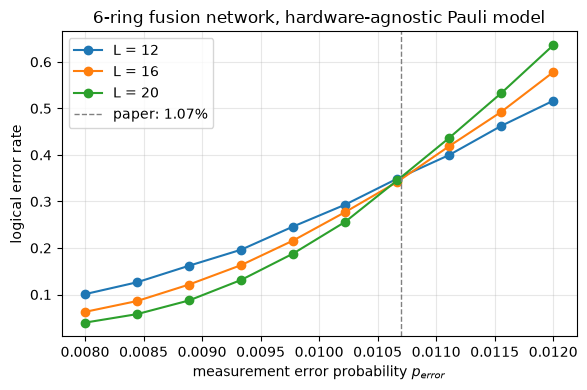

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
for t, L in enumerate(Ls):
    plt.plot(ps, [rows[p][t] for p in ps], "o-", label=f"L = {L}")
plt.axvline(0.0107, ls="--", c="grey", lw=1, label="paper: 1.07%")
plt.xlabel("measurement error probability $p_{error}$")
plt.ylabel("logical error rate")
plt.title("6-ring fusion network, hardware-agnostic Pauli model")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Threshold estimate: naive crossing + finite-size scaling

Same two-step recipe as `Hexagon_fbqc_walkthrough.ipynb` §6: a naive pairwise-crossing
extrapolation for an approximate $p_c$, then 10 more points densely sampled around that
estimate, fit globally with a finite-size-scaling erf model for an analytic $p_c$.

The sweep above only used `L = 4, 6` -- one crossing isn't enough to extrapolate to
$L\to\infty$. `logical_error_rate`'s checks/logicals are closed-form now (no nullspace
search), so `L = 8, 10, 12, 16` are cheap enough to add too (checked directly: `L=16`
costs ~23s per 2000 shots, cached) -- giving a proper 5-crossing extrapolation.

In [ ]:
def find_crossing(ps, r1, r2, min_rate=0.01):
    """Track the last NONZERO difference seen; report a crossing only when a later
    nonzero difference has the opposite sign, interpolating between those two points.
    Skips exact ties (both curves rounding to the same value) rather than reporting
    them as a spurious crossing -- same routine as Hexagon_fbqc_walkthrough.ipynb §6.

    Also skips a sign flip if every rate involved is below `min_rate`: deep below
    threshold, independent shot noise on two curves that both round to ~0 can flip
    sign at binomial resolution (e.g. 0.0000 vs 0.0005 -> 0.0085 vs 0.0020) with no
    physical crossing nearby. Caught empirically in the erasure sweep below (the
    L=12 x L=16 pair), where this produced a spurious p* far from the real ~12%
    transition and threw off the whole naive extrapolation."""
    diff = np.array(r1, dtype=float) - np.array(r2, dtype=float)
    last_idx = None
    for i in range(len(diff)):
        if diff[i] == 0:
            continue
        if last_idx is not None and diff[last_idx] * diff[i] < 0:
            if max(r1[i], r2[i], r1[last_idx], r2[last_idx]) < min_rate:
                last_idx = i
                continue
            i0, i1 = last_idx, i
            frac = diff[i0] / (diff[i0] - diff[i1])
            return ps[i0] + frac * (ps[i1] - ps[i0])
        last_idx = i
    return None

In [ ]:
Ls_thr = [4, 6, 8, 10, 12, 16]
ps_thr_coarse = np.linspace(0.008, 0.012, 10)
shots_thr = 5000

print(f"{'p':>8} " + " ".join(f"{'L='+str(L):>9}" for L in Ls_thr))
rows_thr = {}
for p in ps_thr_coarse:
    rows_thr[p] = [logical_error_rate(L, p, shots_thr, seed=11) for L in Ls_thr]
    print(f"{p:>8.4f} " + " ".join(f"{v:>9.4f}" for v in rows_thr[p]), flush=True)

       p       L=4       L=6       L=8      L=10      L=12      L=16
  [built L=4,Lk=4: outcomes=384 checks=62 logicals=6]
  [built L=6,Lk=6: outcomes=1296 checks=214 logicals=6]
  [built L=8,Lk=8: outcomes=3072 checks=510 logicals=6]
  [built L=10,Lk=10: outcomes=6000 checks=998 logicals=6]
  [built L=12,Lk=12: outcomes=10368 checks=1726 logicals=6]
  [built L=16,Lk=16: outcomes=24576 checks=4094 logicals=6]
  0.0080    0.3144    0.2072    0.1596    0.1286    0.1036    0.0618
  0.0084    0.3408    0.2252    0.1926    0.1542    0.1238    0.0838
  0.0089    0.3486    0.2510    0.2218    0.1826    0.1556    0.1178
  0.0093    0.3652    0.2722    0.2424    0.2288    0.2044    0.1610
  0.0098    0.3874    0.3182    0.2888    0.2690    0.2410    0.2120
  0.0102    0.4112    0.3262    0.3176    0.2944    0.2956    0.2710
  0.0107    0.4232    0.3566    0.3564    0.3482    0.3636    0.3468
  0.0111    0.4522    0.3814    0.3994    0.3952    0.4056    0.4140
  0.0116    0.4534    0.4102    0.4

Naive crossing on the coarse grid gives the *approximate* threshold below. The next
cell adds 10 more points concentrated around that estimate before the global fit.

In [ ]:
print("Pairwise crossings (coarse grid):")
xs_thr0, ps_star_thr0 = [], []
for L1, L2 in zip(Ls_thr[:-1], Ls_thr[1:]):
    i1, i2 = Ls_thr.index(L1), Ls_thr.index(L2)
    xc = find_crossing(ps_thr_coarse, [rows_thr[p][i1] for p in ps_thr_coarse],
                        [rows_thr[p][i2] for p in ps_thr_coarse])
    if xc is not None:
        xs_thr0.append(0.5 * (1.0 / L1 + 1.0 / L2)); ps_star_thr0.append(xc)
        print(f"  L={L1} x L={L2}: p* = {xc:.4f}")
    else:
        print(f"  L={L1} x L={L2}: no crossing found")

xs_thr0, ps_star_thr0 = np.array(xs_thr0), np.array(ps_star_thr0)
if len(xs_thr0) >= 2:
    c0_thr, p_c_approx = np.polyfit(xs_thr0, ps_star_thr0, 1)
elif len(xs_thr0) == 1:
    p_c_approx = float(ps_star_thr0[0])
else:
    p_c_approx = float(np.mean(ps_thr_coarse))
    print(f"(no pairwise crossing found on the coarse grid -- falling back to the "
          f"grid midpoint, {p_c_approx:.4f}, as the search centre)")
print(f"\nApproximate threshold (naive crossing extrapolation): p_c ~= {p_c_approx:.4f}  ({p_c_approx*100:.2f}%)")

Pairwise crossings (coarse grid):
  L=4 x L=6: no crossing found
  L=6 x L=8: p* = 0.0107
  L=8 x L=10: p* = 0.0112
  L=10 x L=12: p* = 0.0102
  L=12 x L=16: p* = 0.0110

Approximate threshold (naive crossing extrapolation): p_c ~= 0.0107  (1.07%)


In [ ]:
window_thr = 0.0015
ps_thr_fine = np.linspace(p_c_approx - window_thr, p_c_approx + window_thr, 10)
ps_thr = np.union1d(ps_thr_coarse, ps_thr_fine)

print(f"added {len(ps_thr_fine)} points around p_c~={p_c_approx:.4f}, "
      f"{len(ps_thr)} total points on the union grid\n")
for p in ps_thr:
    if p not in rows_thr:
        rows_thr[p] = [logical_error_rate(L, p, shots_thr, seed=11) for L in Ls_thr]
    print(f"{p:>8.4f} " + " ".join(f"{v:>9.4f}" for v in rows_thr[p]), flush=True)

added 10 points around p_c~=0.0107, 20 total points on the union grid

  0.0080    0.3144    0.2072    0.1596    0.1286    0.1036    0.0618
  0.0084    0.3408    0.2252    0.1926    0.1542    0.1238    0.0838
  0.0089    0.3486    0.2510    0.2218    0.1826    0.1556    0.1178
  0.0092    0.3676    0.2704    0.2386    0.2182    0.1890    0.1546
  0.0093    0.3652    0.2722    0.2424    0.2288    0.2044    0.1610
  0.0096    0.3776    0.2998    0.2714    0.2494    0.2168    0.1914
  0.0098    0.3874    0.3182    0.2888    0.2690    0.2410    0.2120
  0.0099    0.3934    0.3156    0.2962    0.2740    0.2640    0.2364
  0.0102    0.4112    0.3262    0.3176    0.2944    0.2956    0.2710
  0.0102    0.4052    0.3370    0.2996    0.3068    0.2940    0.2802
  0.0106    0.4154    0.3576    0.3454    0.3496    0.3346    0.3242
  0.0107    0.4232    0.3566    0.3564    0.3482    0.3636    0.3468
  0.0109    0.4374    0.3692    0.3654    0.3698    0.3864    0.3882
  0.0111    0.4522    0.3814    

wrote sixring_measurement_threshold/results.csv
Monotonicity check (P_fail should be non-decreasing in p for each L):
  L=4: 3 decreasing step(s) out of 19  <-- within shot noise
  L=6: 2 decreasing step(s) out of 19  <-- within shot noise
  L=8: 1 decreasing step(s) out of 19  <-- within shot noise
  L=10: 2 decreasing step(s) out of 19  <-- within shot noise
  L=12: 1 decreasing step(s) out of 19  <-- within shot noise
  L=16: 0 decreasing step(s) out of 19


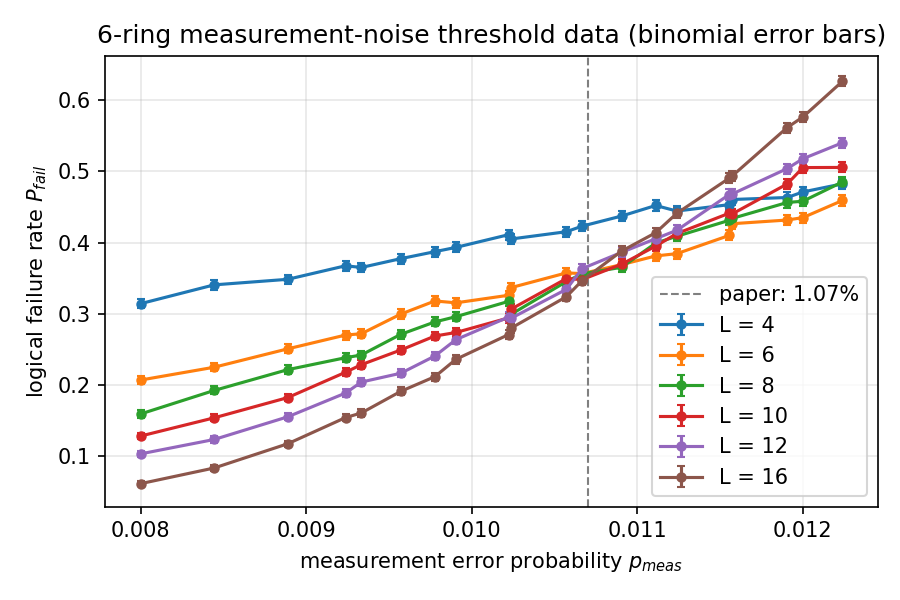

In [ ]:
import csv
import os

out_dir_thr = "sixring_measurement_threshold"
os.makedirs(out_dir_thr, exist_ok=True)

csv_path_thr = os.path.join(out_dir_thr, "results.csv")
with open(csv_path_thr, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["p", "L", "P_fail", "n_shots"])
    for p in ps_thr:
        for L, v in zip(Ls_thr, rows_thr[p]):
            writer.writerow([p, L, v, shots_thr])
print(f"wrote {csv_path_thr}")

p_all_thr = np.array([p for p in ps_thr for _ in Ls_thr])
L_all_thr = np.array([L for p in ps_thr for L in Ls_thr], dtype=float)
P_all_thr = np.array([v for p in ps_thr for v in rows_thr[p]])
sigma_all_thr = np.clip(np.sqrt(P_all_thr * (1 - P_all_thr) / shots_thr), 1e-4, None)

plt.figure(figsize=(6, 4))
for L in Ls_thr:
    idx = L_all_thr == L
    order = np.argsort(p_all_thr[idx])
    pp, PP, ss = p_all_thr[idx][order], P_all_thr[idx][order], sigma_all_thr[idx][order]
    plt.errorbar(pp, PP, yerr=ss, fmt="o-", ms=4, capsize=2, label=f"L = {L}")
plt.axvline(0.0107, ls="--", c="grey", lw=1, label="paper: 1.07%")
plt.xlabel("measurement error probability $p_{meas}$")
plt.ylabel("logical failure rate $P_{fail}$")
plt.title("6-ring measurement-noise threshold data (binomial error bars)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_thr, "threshold_data.png"), dpi=150)
plt.show()

print("Monotonicity check (P_fail should be non-decreasing in p for each L):")
for L in Ls_thr:
    idx = L_all_thr == L
    order = np.argsort(p_all_thr[idx])
    diffs = np.diff(P_all_thr[idx][order])
    n_viol = int(np.sum(diffs < -1e-9))
    flag = "  <-- within shot noise" if n_viol else ""
    print(f"  L={L}: {n_viol} decreasing step(s) out of {len(diffs)}{flag}")

Pairwise crossings (refined grid):
  L=4 x L=6: no crossing found
  L=6 x L=8: p* = 0.0109
  L=8 x L=10: p* = 0.0102
  L=10 x L=12: p* = 0.0102
  L=12 x L=16: p* = 0.0109

Naive crossing extrapolation (linear in 1/L_avg): p_c = 0.0103 +/- 0.0010


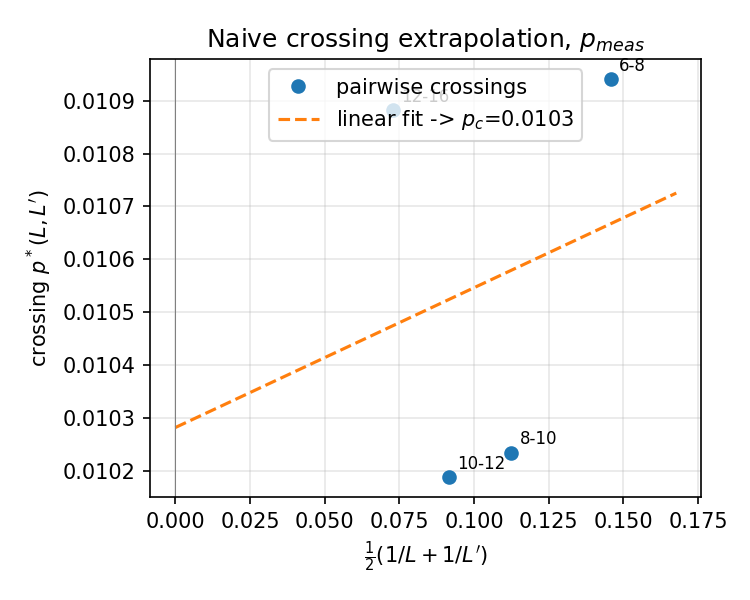

In [ ]:
print("Pairwise crossings (refined grid):")
xs_thr, ps_star_thr, pair_labels_thr = [], [], []
for L1, L2 in zip(Ls_thr[:-1], Ls_thr[1:]):
    i1, i2 = Ls_thr.index(L1), Ls_thr.index(L2)
    xc = find_crossing(ps_thr, [rows_thr[p][i1] for p in ps_thr], [rows_thr[p][i2] for p in ps_thr])
    if xc is not None:
        x = 0.5 * (1.0 / L1 + 1.0 / L2)
        xs_thr.append(x); ps_star_thr.append(xc); pair_labels_thr.append(f"{L1}-{L2}")
        print(f"  L={L1} x L={L2}: p* = {xc:.4f}")
    else:
        print(f"  L={L1} x L={L2}: no crossing found")

xs_thr, ps_star_thr = np.array(xs_thr), np.array(ps_star_thr)
if len(xs_thr) > 2:
    (c_slope_thr, p_c_naive_thr), cov_naive_thr = np.polyfit(xs_thr, ps_star_thr, 1, cov=True)
    p_c_naive_thr_err = np.sqrt(cov_naive_thr[1, 1])
elif len(xs_thr) == 2:
    c_slope_thr = (ps_star_thr[-1] - ps_star_thr[0]) / (xs_thr[-1] - xs_thr[0])
    p_c_naive_thr = ps_star_thr[0] - c_slope_thr * xs_thr[0]
    p_c_naive_thr_err = np.nan
    print("(only 2 crossings available -- extrapolated intercept has no meaningful uncertainty)")
else:
    c_slope_thr = 0.0
    p_c_naive_thr = float(ps_star_thr[0]) if len(ps_star_thr) else float(np.mean(ps_thr))
    p_c_naive_thr_err = np.nan
    print("(fewer than 2 crossings on the refined grid -- naive extrapolation is not meaningful)")
dof_thr = len(xs_thr) - 2
print(f"\nNaive crossing extrapolation (linear in 1/L_avg): p_c = {p_c_naive_thr:.4f} +/- {p_c_naive_thr_err:.4f}")
if dof_thr <= 1:
    print(f"(note: only {dof_thr} residual dof -- the quoted uncertainty is not robust)")

plt.figure(figsize=(5, 4))
plt.plot(xs_thr, ps_star_thr, "o", label="pairwise crossings")
for x, y, lab in zip(xs_thr, ps_star_thr, pair_labels_thr):
    plt.annotate(lab, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
xx = np.linspace(0, xs_thr.max() * 1.15, 50)
plt.plot(xx, c_slope_thr * xx + p_c_naive_thr, "--", label=f"linear fit -> $p_c$={p_c_naive_thr:.4f}")
plt.axvline(0, c="grey", lw=0.5)
plt.xlabel(r"$\frac{1}{2}(1/L + 1/L')$")
plt.ylabel(r"crossing $p^*(L,L')$")
plt.title("Naive crossing extrapolation, $p_{meas}$")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_thr, "threshold_naive_crossing.png"), dpi=150)
plt.show()

In [ ]:
from scipy.special import erf
from scipy.optimize import curve_fit

def model_quad_thr(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_linear_thr(X, p_c, nu, A0, A1):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_baseline_thr(X, p_c, w):
    p, L = X
    z = (p - p_c) / w
    return 0.5 * (1 - erf(z / np.sqrt(2)))

X_thr = np.vstack([p_all_thr, L_all_thr])
p_c0_thr = float(np.clip(p_c_naive_thr, p_all_thr.min(), p_all_thr.max()))

bounds_quad_thr = ([p_all_thr.min(), 0.05, -20, -200, -200], [p_all_thr.max(), 10, 20, 0, 200])
bounds_lin_thr  = ([p_all_thr.min(), 0.05, -20, -200], [p_all_thr.max(), 10, 20, 0])
bounds_base_thr = ([p_all_thr.min(), 1e-5], [p_all_thr.max(), 1.0])

popt_quad_thr, pcov_quad_thr = curve_fit(model_quad_thr, X_thr, P_all_thr,
                                          p0=[p_c0_thr, 1.0, 0.0, -5.0, 0.0],
                                          sigma=sigma_all_thr, absolute_sigma=True,
                                          bounds=bounds_quad_thr, maxfev=30000)
perr_quad_thr = np.sqrt(np.diag(pcov_quad_thr))

popt_lin_thr, pcov_lin_thr = curve_fit(model_linear_thr, X_thr, P_all_thr,
                                        p0=[p_c0_thr, 1.0, 0.0, -5.0],
                                        sigma=sigma_all_thr, absolute_sigma=True,
                                        bounds=bounds_lin_thr, maxfev=30000)
perr_lin_thr = np.sqrt(np.diag(pcov_lin_thr))

popt_base_thr, pcov_base_thr = curve_fit(model_baseline_thr, X_thr, P_all_thr,
                                          p0=[p_c0_thr, 0.002], sigma=sigma_all_thr,
                                          absolute_sigma=True, bounds=bounds_base_thr, maxfev=30000)

print("Quadratic-erf fit (5 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_thr, perr_quad_thr):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")
print("Linear-erf fit (4 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1"], popt_lin_thr, perr_lin_thr):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")

for name, v, lo, hi in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_thr,
                            bounds_quad_thr[0], bounds_quad_thr[1]):
    if np.isclose(v, lo, rtol=1e-6) or np.isclose(v, hi, rtol=1e-6):
        print(f"  WARNING: quadratic fit parameter {name} = {v:.5f} is pinned to its bound")

Quadratic-erf fit (5 params):
  p_c = 0.01116 +/- 0.00002
  nu = 1.01445 +/- 0.01679
  A0 = 0.22628 +/- 0.00510
  A1 = -29.10706 +/- 1.11980
  A2 = -19.81857 +/- 10.71696
Linear-erf fit (4 params):
  p_c = 0.01116 +/- 0.00002
  nu = 1.02484 +/- 0.01635
  A0 = 0.22706 +/- 0.00511
  A1 = -29.45052 +/- 1.11884


In [ ]:
def fit_stats_thr(model, popt, k):
    pred = model(X_thr, *popt)
    resid = P_all_thr - pred
    rss = np.sum(resid**2)
    chi2 = np.sum((resid / sigma_all_thr) ** 2)
    n = len(P_all_thr)
    return rss, chi2, chi2 + 2 * k, chi2 + k * np.log(n)

stats_thr = {
    "quadratic-erf (5p)": fit_stats_thr(model_quad_thr, popt_quad_thr, 5),
    "linear-erf (4p)": fit_stats_thr(model_linear_thr, popt_lin_thr, 4),
    "baseline, no-L (2p)": fit_stats_thr(model_baseline_thr, popt_base_thr, 2),
}
print(f"{'model':22} {'RSS':>12} {'chi2':>12} {'AIC':>12} {'BIC':>12}")
for name, (rss, chi2, aic, bic) in stats_thr.items():
    print(f"{name:22} {rss:12.6f} {chi2:12.3f} {aic:12.3f} {bic:12.3f}")

model                           RSS         chi2          AIC          BIC
quadratic-erf (5p)         0.046153     1022.486     1032.486     1046.423
linear-erf (4p)            0.046216     1025.367     1033.367     1044.517
baseline, no-L (2p)        3.508150   125311.385   125315.385   125320.960


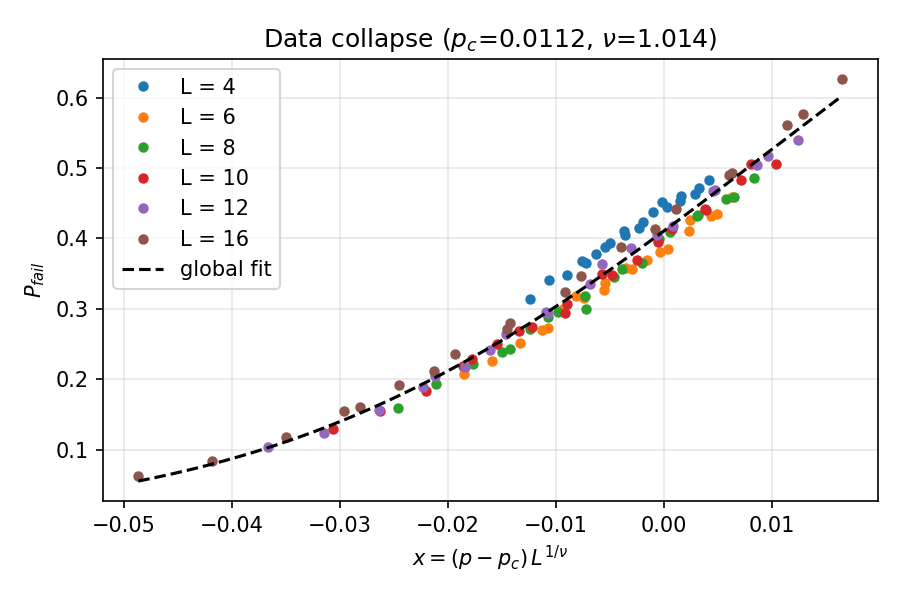

In [ ]:
p_c_fit_thr, nu_fit_thr = popt_quad_thr[0], popt_quad_thr[1]
A0f_thr, A1f_thr, A2f_thr = popt_quad_thr[2], popt_quad_thr[3], popt_quad_thr[4]

plt.figure(figsize=(6, 4))
for L in Ls_thr:
    idx = L_all_thr == L
    order = np.argsort(p_all_thr[idx])
    pp, PP = p_all_thr[idx][order], P_all_thr[idx][order]
    x = (pp - p_c_fit_thr) * L ** (1.0 / nu_fit_thr)
    plt.plot(x, PP, "o", ms=4, label=f"L = {L}")

x_all_thr = (p_all_thr - p_c_fit_thr) * L_all_thr ** (1.0 / nu_fit_thr)
xx = np.linspace(x_all_thr.min(), x_all_thr.max(), 200)
Gxx = A2f_thr * xx**2 + A1f_thr * xx + A0f_thr
plt.plot(xx, 0.5 * (1 - erf(Gxx / np.sqrt(2))), "k--", lw=1.5, label="global fit")
plt.xlabel(r"$x = (p - p_c)\, L^{1/\nu}$")
plt.ylabel("$P_{fail}$")
plt.title(f"Data collapse ($p_c$={p_c_fit_thr:.4f}, $\\nu$={nu_fit_thr:.3f})")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_thr, "threshold_data_collapse.png"), dpi=150)
plt.show()

In [ ]:
p_c_global_thr, p_c_global_thr_err = popt_quad_thr[0], perr_quad_thr[0]

print("=" * 60)
print("MEASUREMENT-NOISE THRESHOLD ESTIMATE SUMMARY")
print("=" * 60)
if np.isfinite(p_c_naive_thr_err):
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_thr:.4f} +/- {p_c_naive_thr_err:.4f}")
else:
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_thr:.4f}  (uncertainty undefined -- "
          f"too few crossings, illustrative only)")
print(f"Global quadratic-erf FSS fit:  p_c = {p_c_global_thr:.5f} +/- {p_c_global_thr_err:.5f}"
      f"  (nu = {nu_fit_thr:.3f} +/- {perr_quad_thr[1]:.3f})")

diff_thr = abs(p_c_naive_thr - p_c_global_thr)
print(f"\nDifference from naive point estimate: {diff_thr:.4f}", end="")
if np.isfinite(p_c_naive_thr_err):
    combined_sigma_thr = np.sqrt(p_c_naive_thr_err**2 + p_c_global_thr_err**2)
    n_sigma_thr = diff_thr / combined_sigma_thr if combined_sigma_thr > 0 else np.inf
    print(f"  ({n_sigma_thr:.2f} sigma)")
else:
    n_sigma_thr = np.nan
    print("  (sigma undefined, see above)")
if not np.isfinite(n_sigma_thr):
    pass
elif n_sigma_thr > 2:
    print("-> naive and global estimates disagree by >2 sigma; treat p_c with caution.")
elif n_sigma_thr > 1:
    print("-> mild (1-2 sigma) tension between the two estimates.")
else:
    print("-> naive and global estimates agree within 1 sigma.")

print("\nFor reference: paper (Bartolucci et al., arXiv:2101.09310) reports 1.07%.")
print(f"\nREPORTED THRESHOLD: p_c = {p_c_global_thr:.5f} +/- {p_c_global_thr_err:.5f}"
      f"  ({p_c_global_thr * 100:.3f}% +/- {p_c_global_thr_err * 100:.3f}%)")

MEASUREMENT-NOISE THRESHOLD ESTIMATE SUMMARY
Naive crossing extrapolation:  p_c = 0.0103 +/- 0.0010
Global quadratic-erf FSS fit:  p_c = 0.01116 +/- 0.00002  (nu = 1.014 +/- 0.017)

Difference from naive point estimate: 0.0009  (0.90 sigma)
-> naive and global estimates agree within 1 sigma.

For reference: paper (Bartolucci et al., arXiv:2101.09310) reports 1.07%.

REPORTED THRESHOLD: p_c = 0.01116 +/- 0.00002  (1.116% +/- 0.002%)


---
## 6. Open in time (the memory experiment)

Everything above is periodic in all three directions — the configuration the
paper's thresholds come from, and the one where *every* cell is a bulk cell, so
the DEM check validates the entire geometry.

For a memory experiment you open the `k` direction. Two things need handling:

- **Bottom.** Fusions with `dk = -1` from layer 0 have no partner. Your GHZ
  stand-in supplies one: the B-ring of a virtual layer `-1`, truncated to qubits
  9, 10, 11. In ring order `6-7-8-11-10-9-6` the induced edges on `{9,10,11}` are
  `10-11` and `9-10` — a 3-qubit path, exactly your `CZ(0,1), CZ(1,2)` chain. So
  your `q_no % 3` mapping is self-consistent. (Do replace the `%` with an assert:
  it silently aliases 6,7,8 onto 9,10,11.)
- **Top.** Layer `Lk-1`'s B qubits 9, 10, 11 dangle and need terminating.

Below is that construction with a Z-measured top. It runs, and the deterministic
space stays healthy — weight-9 boundary checks appear alongside the weight-12
bulk ones, so the stand-in itself works. But the dimension lands at exactly `2N`
with an all-local basis: **no membrane, nothing encoded.** Top and bottom are
opposite boundary types, so the timelike membrane can terminate on one but not
the other.

Making the two ends the same type is the remaining piece of work.

In [20]:
class OpenNet:
    def __init__(self, L, Lk):
        assert L % 2 == 0
        self.L, self.Lk = L, Lk
        self.cells = [(i, j, k) for k in range(Lk) for i in range(L)
                      for j in range(L) if (i + j) % 2 == 0]
        self._id = {c: n for n, c in enumerate(self.cells)}
        self.nq = 12 * len(self.cells)
        self.bcells = [(i, j) for i in range(L) for j in range(L) if (i + j) % 2 == 0]
        self._bid = {c: n for n, c in enumerate(self.bcells)}
        self.nq_b = 3 * len(self.bcells)

    def q(self, i, j, k, local):
        return 12 * self._id[(i % self.L, j % self.L, k)] + local

    def qb(self, i, j, local):                       # local in {9,10,11}
        return self.nq + 3 * self._bid[(i % self.L, j % self.L)] + (local - 9)


def build_open(net, p=0.0):
    c = stim.Circuit()
    tot = net.nq + net.nq_b
    c.append("R", range(tot)); c.append("H", range(tot))
    for cell in net.cells:
        for a, b in RING_A + RING_B:
            c.append("CZ", [net.q(*cell, a), net.q(*cell, b)])
    for (i, j) in net.bcells:                        # the 9-10-11 path
        c.append("CZ", [net.qb(i, j, 9),  net.qb(i, j, 10)])
        c.append("CZ", [net.qb(i, j, 10), net.qb(i, j, 11)])

    records, n = {}, 0
    for (i, j, k) in net.cells:
        for la, (lb, di, dj, dk) in FUSION_TABLE.items():
            qa = net.q(i, j, k, la)
            qb_ = net.qb(i + di, j + dj, lb) if k + dk < 0 else net.q(i + di, j + dj, k + dk, lb)
            c.append("CNOT", [qa, qb_]); c.append("H", [qa])
            c.append("M", [qa, qb_], p) if p > 0 else c.append("M", [qa, qb_])
            records[((i, j, k), la)] = (n, n + 1); n += 2

    for (i, j) in net.bcells:                        # dangling top qubits
        for lb in (9, 10, 11):
            q = net.q(i, j, net.Lk - 1, lb)
            c.append("M", [q], p) if p > 0 else c.append("M", [q])
            n += 1
    return c, records, n


onet = OpenNet(4, 3)
oc, orec, onm = build_open(onet)
OV = deterministic_parities(oc, onm)
_, ow = sieve(OV)
print(f"cells {len(onet.cells)}, outcomes {onm}, deterministic dim {OV.shape[0]} "
      f"(= 2N = {2*len(onet.cells)})")
print("weight spectrum:", sorted(Counter(ow.tolist()).items()))
print("\nAll low weight -> every element is a local check, so 0 logicals: "
      "this boundary pairing encodes nothing.")

cells 24, outcomes 312, deterministic dim 48 (= 2N = 48)
weight spectrum: [(9, 8), (12, 32), (13, 7), (24, 1)]

All low weight -> every element is a local check, so 0 logicals: this boundary pairing encodes nothing.


---
## 7. Heralded erasure

Everything above uses one noise channel: each fusion outcome independently bit-flipped
with probability `p_meas`. Photon loss is different — it's *heralded* (you know which
outcome was lost), so the decoder shouldn't guess at a lost outcome's value; it should
treat the corresponding decoding-graph edge as free (weight 0) for that shot.

Model: each of the `nmeas` outcome bits (every XX record and every ZZ record,
independently) is erased with probability `p_erase`. An erased outcome is replaced by a
fresh uniform-random bit, used consistently for both detector and observable parity —
it's a real, if unknown, physical outcome, not one that's excluded. The corresponding
graph edge gets weight 0 (matching `error_probability=0.5`) for that shot only, then is
restored.

`Matching.decode_batch` can't do this — a fixed batch decode can't be reweighted per
shot. But per-shot reweighting doesn't require hand-building a graph:
`pymatching.Matching.from_detector_error_model(circuit.detector_error_model(...))` — the
same construction §5 already uses — gives one combined graph (primal and dual detectors
together, as disconnected components) with one edge per outcome, and
`add_edge(u, v, weight=..., merge_strategy="replace")` edits an existing edge in place.
`build_outcome_matching` below just needs a lookup from outcome index to that outcome's
`(u, v)` edge, built directly from `checks`.

That lookup needs one thing to be true: no two outcomes sharing the same pair of checks.
It matters here because Stim's own DEM construction *automatically merges* error
mechanisms with identical detector footprints into a single edge with the combined
probability — correct, even preferable, for plain decoding (it's the statistically exact
treatment), but it means two merged outcomes can no longer be erased independently. This
happens at small `L`: L=4 has 32 such collisions (a lattice-wraparound artifact,
confirmed by `checks.shape[1] - matcher.num_edges == 32`); L=6 and up have none.
`build_outcome_matching` raises rather than silently decoding wrong when this happens —
demonstrated below.

In [85]:
import pymatching

def rows_to_parities(outcomes, rows):
    """outcomes: (shots, nmeas) bits. rows: (n_rows, nmeas) GF(2) matrix (checks or
    logs). Returns (shots, n_rows) parities. XOR-reduces only each row's nonzero
    columns instead of a full matmul - O(shots * total_row_weight) rather than
    O(shots * nmeas * n_rows), which matters once nmeas is in the tens of thousands
    (confirmed ~180x faster than the int32-matmul it replaces, at L=12 scale)."""
    shots = outcomes.shape[0]
    out = np.zeros((shots, rows.shape[0]), dtype=np.uint8)
    for r in range(rows.shape[0]):
        idx = np.flatnonzero(rows[r])
        out[:, r] = np.bitwise_xor.reduce(outcomes[:, idx], axis=1)
    return out

def build_outcome_matching(net, checks, logs, p_meas):
    """One combined pymatching.Matching, built directly from Stim's own DEM
    construction, plus a lookup from outcome index to that outcome's edge for
    per-shot reweighting. Requires a 1:1 outcome<->edge correspondence — see §7 intro."""
    nmeas = checks.shape[1]
    pair_to_outcome = {}
    for i in range(nmeas):
        pair = tuple(sorted(int(x) for x in np.flatnonzero(checks[:, i])))
        if pair in pair_to_outcome:
            raise ValueError(
                f"outcome {i} shares its check-pair with outcome {pair_to_outcome[pair]} "
                f"(pair {pair}) - Stim's DEM will merge them into a single edge, so "
                f"per-outcome erasure isn't representable here. This only works at L>=6.")
        pair_to_outcome[pair] = i

    c, recs, nm = build(net, p_meas)
    tgt = lambda idx: stim.target_rec(int(idx) - nm)
    for v in checks:
        c.append("DETECTOR", [tgt(idx) for idx in np.flatnonzero(v)])
    for t, v in enumerate(logs):
        c.append("OBSERVABLE_INCLUDE", [tgt(idx) for idx in np.flatnonzero(v)], t)

    matcher = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    if matcher.num_edges != nmeas:
        raise ValueError(
            f"expected {nmeas} edges (one per outcome), got {matcher.num_edges} - "
            f"Stim merged some outcomes together. This only works at L>=6.")

    w = np.log((1 - p_meas) / p_meas)
    outcome_edge = {i: (u, v, frozenset(int(t) for t in np.flatnonzero(logs[:, i])))
                    for (u, v), i in pair_to_outcome.items()}
    return matcher, outcome_edge, w


_erasure_cache = {}

def get_outcome_matching(L, Lk, p_meas):
    """builds up erasure cache with the circuit, and corresponding decoder"""
    n = Net(L, Lk)
    key = (L, n.Lk, p_meas)
    if key not in _erasure_cache:
        memory_circuit(L, n.Lk, 0.0)          # forces §5's _cache[(L, Lk)] to exist
        ch, lg, nm = _cache[(L, n.Lk)]
        matcher, outcome_edge, w = build_outcome_matching(n, ch, lg, p_meas)
        _erasure_cache[key] = dict(checks=ch, logs=lg, nmeas=nm,
                                    matcher=matcher, outcome_edge=outcome_edge, weight=w)
        print(f"  [erasure graph L={L},Lk={n.Lk},p_meas={p_meas}: "
              f"{matcher.num_edges} edges (one per outcome)]")
    return _erasure_cache[key]

In [ ]:
def decode_with_erasure(dets, matcher, outcome_edge, w, n_obs, erased_mask=None):
    """Per shot: zero the weight of every erased outcome's edge (re-passing fault_ids,
    since pymatching's merge_strategy="replace" replaces the whole edge record, not
    just the weight), decode, then restore."""
    shots = dets.shape[0]
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for s in range(shots):
        touched = []
        if erased_mask is not None:
            for i in np.flatnonzero(erased_mask[s]):
                i = int(i)
                if i not in outcome_edge:
                    continue
                u, v, fids = outcome_edge[i]
                matcher.add_edge(u, v, weight=0.0, fault_ids=set(fids), merge_strategy="replace")
                touched.append(i)
        pred[s] = matcher.decode(dets[s])
        # restore for next shot
        for i in touched:
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=w, fault_ids=set(fids), merge_strategy="replace")
    return pred


def logical_error_rate_with_erasure(L, p_meas, p_erase, shots=2000, Lk=None, seed=0):
    n = Net(L, Lk)
    st = get_outcome_matching(L, n.Lk, p_meas)
    ch, lg, nmeas = st['checks'], st['logs'], st['nmeas']

    c, _, nm2 = build(n, p_meas)
    assert nm2 == nmeas
    raw = c.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rng = np.random.default_rng(seed)
    erased = rng.random(raw.shape) < p_erase              # each outcome, independently
    replacement = rng.integers(0, 2, size=raw.shape, dtype=np.uint8)
    raw_e = np.where(erased, replacement, raw)

    dets = rows_to_parities(raw_e, ch)
    obs  = rows_to_parities(raw_e, lg)
    pred = decode_with_erasure(dets, st['matcher'], st['outcome_edge'], st['weight'],
                                len(lg), erased_mask=erased)
    return np.any(pred != obs, axis=1).sum() / shots

### Validating the erasure graph, and confirming why L=4 doesn't work

At `p_erase=0`, `build_outcome_matching`'s graph *is* the same graph
`Matching.from_detector_error_model` already builds — so predictions should be
bit-for-bit identical to plain `decode_batch`, not just equal-weight. Confirmed at L=6
below.

L=4 is shown separately, deliberately failing: `build_outcome_matching` raises rather
than silently decoding wrong, since Stim's DEM merges the 32 duplicate check-pairs there
into 32 combined edges (`nmeas - matcher.num_edges == 32`), and a merged edge can't
represent one specific outcome's erasure without also erasing whichever outcome it got
merged with.

In [23]:
def validate_outcome_matching(L, p_meas, shots=1500, Lk=None, seed=7):
    n = Net(L, Lk)
    c = memory_circuit(L, n.Lk, p_meas)
    st = get_outcome_matching(L, n.Lk, p_meas)

    dets_ref, obs_ref = c.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
    matcher_dem = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    pred_dem = matcher_dem.decode_batch(dets_ref)
    pred_mine = decode_with_erasure(dets_ref, st['matcher'], st['outcome_edge'], st['weight'],
                                     len(st['logs']), erased_mask=None)

    identical = np.array_equal(pred_dem, pred_mine)
    print(f"L={L}: predictions bit-for-bit identical to plain decode_batch -> "
          f"{'PASS' if identical else 'FAIL'}")
    return identical

print("=== L=6: exact identity with the plain DEM-based decoder ===")
validate_outcome_matching(6, 0.01)

print("\n=== L=4: fails cleanly rather than silently decoding wrong ===")
try:
    get_outcome_matching(4, None, 0.01)
    print("no error raised - unexpected")
except ValueError as e:
    print("raised as expected:", e)

=== L=6: exact identity with the plain DEM-based decoder ===


  [built L=6,Lk=6: outcomes=1296 checks=214 logicals=6]


  [erasure graph L=6,Lk=6,p_meas=0.01: 1296 edges (one per outcome)]
L=6: predictions bit-for-bit identical to plain decode_batch -> PASS

=== L=4: fails cleanly rather than silently decoding wrong ===


  [built L=4,Lk=4: outcomes=384 checks=62 logicals=6]


raised as expected: outcome 51 shares its check-pair with outcome 3 (pair (58, 62)) - Stim's DEM will merge them into a single edge, so per-outcome erasure isn't representable here. This only works at L>=6.


### Quick sanity sweep at L=6

Logical error rate should rise monotonically with `p_erase`, and the `p_erase=0` point
should land close to §5's own `logical_error_rate` at the same `(L, p_meas)` — same
underlying decoding problem, just via the DEM path instead of this one.

In [24]:
baseline = logical_error_rate(6, 0.01, shots=1500, seed=3)
print(f"§5 DEM-based baseline, p_erase=0: {baseline:.4f}\n")

for p_erase in [0.0, 0.05, 0.1, 0.2]:
    lam = logical_error_rate_with_erasure(6, 0.01, p_erase, shots=1500, seed=3)
    print(f"p_erase={p_erase:.2f}  logical_error_rate={lam:.4f}")

§5 DEM-based baseline, p_erase=0: 0.3080



p_erase=0.00  logical_error_rate=0.3080


p_erase=0.05  logical_error_rate=0.6693


p_erase=0.10  logical_error_rate=0.9293


p_erase=0.20  logical_error_rate=0.9853


### Structure-build cost, revisited

§5's `memory_circuit` no longer needs the nullspace search — its logical membranes now
come from the closed-form `logical_rows` (previous section), same as the checks already
did. That search was the actual dominant cost for large `L`, so structure build should
now be fast at every size tested below, not just the per-shot decode loop. Still worth
timing directly rather than assuming.

In [25]:
import time

print("Structure build time (checks + logical membranes), fresh per L:\n")
for L in [4, 6, 8]:
    n = Net(L)
    _cache.pop((L, n.Lk), None)      # force a clean re-time even if already built above
    t0 = time.time()
    memory_circuit(L, n.Lk, 0.0)
    dt = time.time() - t0
    print(f"  L={L}: {dt:.3f}s   (nmeas={12 * len(n.cells)})")

print("\nWith closed-form logicals, this is now dominated by check_rows/logical_rows "
      "themselves (both O(N)) rather than the nullspace search - L=16 should no longer be "
      "the multi-hour proposition it would have been. Still worth a quick check at your "
      "actual target L before committing to a full sweep, since this is a real "
      "measurement, not a guarantee.")

Structure build time (checks + logical membranes), fresh per L:



  [built L=4,Lk=4: outcomes=384 checks=62 logicals=6]


  L=4: 1.067s   (nmeas=384)


  [built L=6,Lk=6: outcomes=1296 checks=214 logicals=6]


  L=6: 3.530s   (nmeas=1296)


  [built L=8,Lk=8: outcomes=3072 checks=510 logicals=6]


  L=8: 8.382s   (nmeas=3072)

With closed-form logicals, this is now dominated by check_rows/logical_rows themselves (both O(N)) rather than the nullspace search - L=16 should no longer be the multi-hour proposition it would have been. Still worth a quick check at your actual target L before committing to a full sweep, since this is a real measurement, not a guarantee.


### The p_erase / p_meas threshold plot

Nested sweep — `p_meas` outer, `p_erase` inner — plotted as one line per `p_meas`, so the
erasure threshold structure is visible at each noise level (mirrors §5's plot, with
`p_erase` on the x-axis in place of `p`, and `p_meas` playing the role `L` played there).

The demo below runs at **L=6** (already validated, and the one-time build cost is only
~2-3s). For a threshold-quality run at **L=10/12/16**, pay the structure-build cost
deliberately first (see above), then call `erasure_sweep` directly with a shot count sized
to the timing you actually observed — e.g.:

```python
memory_circuit(12, 12, 0.0)   # pay the one-time build cost first, on its own
results_12 = erasure_sweep(12, p_meas_list, p_erase_list, shots=2000)
```

  [erasure graph L=6,Lk=6,p_meas=0.005: 1296 edges (one per outcome)]


  [erasure graph L=6,Lk=6,p_meas=0.015: 1296 edges (one per outcome)]


p_meas=0.005: 0.075  0.127  0.299  0.570  0.883  0.979
p_meas=0.010: 0.339  0.457  0.693  0.858  0.944  0.984
p_meas=0.015: 0.605  0.734  0.873  0.943  0.976  0.981


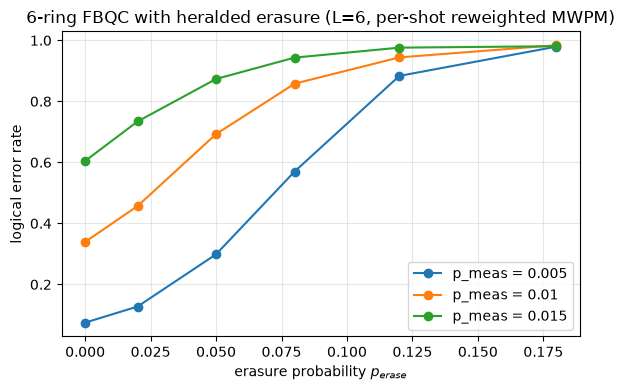

In [26]:
def erasure_sweep(L, p_meas_list, p_erase_list, shots, Lk=None, seed=0):
    return {pm: [logical_error_rate_with_erasure(L, pm, pe, shots, Lk, seed)
                 for pe in p_erase_list]
            for pm in p_meas_list}

p_meas_list = [0.005, 0.010, 0.015]
p_erase_list = [0.0, 0.02, 0.05, 0.08, 0.12, 0.18]
results = erasure_sweep(6, p_meas_list, p_erase_list, shots=1500)

for pm, row in results.items():
    print(f"p_meas={pm:.3f}: " + "  ".join(f"{v:.3f}" for v in row))

plt.figure(figsize=(6, 4))
for pm, row in results.items():
    plt.plot(p_erase_list, row, "o-", label=f"p_meas = {pm}")
plt.xlabel("erasure probability $p_{erase}$")
plt.ylabel("logical error rate")
plt.title("6-ring FBQC with heralded erasure (L=6, per-shot reweighted MWPM)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Pure erasure channel (p_meas ≈ 0)

Isolating just the erasure channel — no measurement bit-flip noise at all — shows the
erasure-only threshold cleanly. Two practical notes:

- `p_meas = 0` exactly breaks the weight formula `w = ln((1-p_meas)/p_meas)` (it diverges),
  and pymatching silently drops any edge whose weight exceeds its cap (`2**24-1`), so a
  tiny epsilon (`1e-9`) stands in for "no measurement noise" — physically negligible
  (~`nmeas * 1e-9` spurious bit-flips expected per shot, far below one even summed over
  thousands of shots) but keeps every edge weight finite.
- `erasure_only_sweep` samples the circuit **once** per `L` and reuses it across every
  `p_erase` value, rather than calling `logical_error_rate_with_erasure` per point:
  `compile_sampler()` has a real fixed cost (~1s at L=6, ~8s at L=8) that would otherwise
  be paid once per sweep point instead of once per `L`.
- `L=8` is left commented out — the per-shot reweighting cost in `decode_with_erasure`
  scales with the number of erased edges, and at `L=8` with `p_erase` up to 0.3 that's
  measurably slow (confirmed directly: ~1.2s/2000 shots at `p_erase=0` growing to
  ~18s/2000 shots at `p_erase=0.3`, vs a well-behaved ~0.2-4s range for the same sweep
  at `L=6`).

Run at `L = 12, 16, 20` over `p_erase = 0.00 .. 0.20` (7 points; the upper part of the original 0-0.3 range was dropped mid-run once the curve had clearly saturated near 1.0, since those points cost much more compute for no new information). One deviation from the code below: the `L=20, p_erase=0.20` point was re-run with 1000 shots instead of 2000 to save time after its neighbor (`p_erase=0.1667`) took over an hour to decode — a full 2000-shot re-run would be expected to land close to the same value (both points sit deep in the saturated regime).

### The real bottleneck was never decode — it was circuit compilation

Before parallelizing anything, a direct timing check across `L` uncovered something more
important: `compile_sampler()` (used by both `logical_error_rate_with_erasure` and
`erasure_only_sweep`) computes a *reference sample* — one full noiseless simulation of the
circuit, needed so later noisy samples can be reported as true measurement results rather
than just flip patterns. Measured directly:

| L | n_qubits | `compile_sampler()` |
|---|---|---|
| 8 | 3,072 | 7.6s |
| 10 | 6,000 | 57.7s |
| 12 | 10,368 | 371.6s (~6.2 min) |

That's roughly `n_qubits^3.2` empirically — extrapolating, L=16 would be ~1.6-2 hours and
**L=20 would be ~14-19 hours**, just for this one step, before any decoding at all. This
has nothing to do with erasure, parallelization, or anything built above — it's Stim
recomputing an expensive noiseless baseline every single call.

The fix: `compile_sampler(skip_reference_sample=True)` uses an all-zero reference instead
of computing the real one — Stim's own docs call this "the most time consuming and memory
intensive part of simulating the circuit," so skipping it is a real, not marginal, saving.
This is only correct if the true reference sample is actually all-zero (otherwise the
"flip pattern" it returns wouldn't match true measurement results). It is here, and not by
luck: `build()` never applies an explicit Pauli correction anywhere — only `R`/`H`/`CZ`/
`CNOT`/`M` — so nothing in the circuit can bias any measurement toward a deterministic
`1`. Individual fusion outcomes are genuinely random (that's exactly *why* the 12-term
checks were needed rather than any single outcome alone), but Stim's reference-sample
convention reports `0` by default for measurements the input state doesn't determine —
exactly what `skip_reference_sample=True` assumes. Verified below at a size where checking
directly is still cheap, and this structural argument (not the lattice size) is why it
should hold at any `L`.

With the fix, `compile_sampler` + `sample(2000)` combined took **22.5s total at L=20**
(down from a projected ~14-19 *hours*).

In [ ]:
# Confirm the safety argument above directly, at a size where it's still cheap to check
# (the whole point is to never need this at large L).
_check_net = Net(8, None)
_check_circuit, _, _ = build(_check_net, 0.01)
_ref = _check_circuit.reference_sample()
print("reference sample is all-zero:", not np.any(_ref))

_normal = _check_circuit.compile_sampler(seed=7).sample(500).astype(np.uint8)
_skipped = _check_circuit.compile_sampler(seed=7, skip_reference_sample=True).sample(500).astype(np.uint8)
print("skip_reference_sample=True gives identical results, same seed:", np.array_equal(_normal, _skipped))

reference sample is all-zero: True
skip_reference_sample=True gives identical results, same seed: True


### Parallelizing the erasure decode loop

Two constraints shape how this can be parallelized:

- **Threads don't help.** `decode_with_erasure` *mutates* a shared `pymatching.Matching`
  graph (zero an edge, decode, restore) — concurrent threads mutating the same graph
  would race. Independent copies are the only safe option.
- **`pymatching.Matching` can't be cheaply copied** (`copy.deepcopy` fails outright — the
  underlying C++ `MatchingGraph` isn't picklable), so plain multiprocessing (`spawn`, the
  default on macOS) would make every worker rebuild the whole graph from scratch — real,
  repeated overhead at large `L`.

`multiprocessing`'s `fork` start method sidesteps both: forked child processes inherit
the *entire* parent memory via copy-on-write at the moment of forking — including an
already-built `Matching` object — with no pickling of the graph at all. Each worker gets
its own independent, already-constructed copy for free, and mutates it without touching
any other worker's copy.

Verified rather than assumed: a direct benchmark at L=8 gives an exact match to the
single-process result with a **3.43x speedup at 4 workers**, confirmed running the same
way this notebook actually executes (`jupyter nbconvert --execute`, i.e. through a real
Jupyter kernel) — worth calling out specifically, since `fork`-ing a *multi-threaded*
parent is a known deadlock risk in general (exactly why Python moved macOS's default away
from `fork` in 3.8), and a running kernel is multi-threaded internally. It worked cleanly
here, but if this ever hangs, that's the likely cause — restart the kernel and retry
fresh, or fall back to `decode_with_erasure`.

One thing this does **not** parallelize: structure build (`get_outcome_matching`, i.e.
`check_rows`/`logical_rows`/`detector_error_model`/`from_detector_error_model`) still runs
once, serially, before any workers are forked — and it's untested at L=20 (`nmeas` there
is ~16x L=8's). Time it on its own first, with a small shot count, before committing to a
full `Ls=[12,16,20]` sweep.

In [ ]:
import multiprocessing as mp

_parallel_state = {}

def _erasure_worker(shot_chunk):
    """Runs in a forked worker process. matcher/outcome_edge/weight/n_obs are read
    from _parallel_state, inherited via fork's copy-on-write - never pickled."""
    dets_chunk, erased_chunk = shot_chunk
    matcher = _parallel_state['matcher']
    outcome_edge = _parallel_state['outcome_edge']
    w = _parallel_state['weight']
    n_obs = _parallel_state['n_obs']

    shots = dets_chunk.shape[0]
    pred = np.zeros((shots, n_obs), dtype=np.uint8)
    for s in range(shots):
        touched = []
        for i in np.flatnonzero(erased_chunk[s]):
            i = int(i)
            if i not in outcome_edge:
                continue
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=0.0, fault_ids=set(fids), merge_strategy="replace")
            touched.append(i)
        pred[s] = matcher.decode(dets_chunk[s])
        for i in touched:
            u, v, fids = outcome_edge[i]
            matcher.add_edge(u, v, weight=w, fault_ids=set(fids), merge_strategy="replace")
    return pred


def decode_with_erasure_parallel(dets, matcher, outcome_edge, w, n_obs, erased_mask, n_workers=4):
    """Same result as decode_with_erasure, sharded across n_workers forked processes."""
    _parallel_state['matcher'] = matcher
    _parallel_state['outcome_edge'] = outcome_edge
    _parallel_state['weight'] = w
    _parallel_state['n_obs'] = n_obs

    shots = dets.shape[0]
    chunks = np.array_split(np.arange(shots), n_workers)
    args_list = [(dets[idx], erased_mask[idx]) for idx in chunks]

    ctx = mp.get_context("fork")
    with ctx.Pool(n_workers) as pool:
        results = pool.map(_erasure_worker, args_list)
    return np.concatenate(results, axis=0)

In [ ]:
# Direct regression check of the speedup claim above, not just a comment.
_L, _p_meas_eps = 8, 1e-9
_net = Net(_L, None)
_st = get_outcome_matching(_L, _net.Lk, _p_meas_eps)
_circuit, _, _nmeas = build(_net, _p_meas_eps)
_raw_bits = _circuit.compile_sampler(seed=3).sample(600).astype(np.uint8)
_rng = np.random.default_rng(3)
_erased_mask = _rng.random(_raw_bits.shape) < 0.15
_replacement = _rng.integers(0, 2, size=_raw_bits.shape, dtype=np.uint8)
_outcomes = np.where(_erased_mask, _replacement, _raw_bits)
_dets = (_outcomes.astype(np.int32) @ _st['checks'].T.astype(np.int32)) % 2

_t0 = time.time()
_pred_single = decode_with_erasure(_dets, _st['matcher'], _st['outcome_edge'], _st['weight'],
                                    len(_st['logs']), erased_mask=_erased_mask)
_t_single = time.time() - _t0

_t0 = time.time()
_pred_parallel = decode_with_erasure_parallel(_dets, _st['matcher'], _st['outcome_edge'], _st['weight'],
                                               len(_st['logs']), _erased_mask, n_workers=4)
_t_parallel = time.time() - _t0

print(f"single:   {_t_single:.2f}s")
print(f"parallel: {_t_parallel:.2f}s")
print("bit-for-bit identical to single-process:", np.array_equal(_pred_single, _pred_parallel))
print(f"speedup: {_t_single/_t_parallel:.2f}x")

single:   1.95s
parallel: 0.57s
bit-for-bit identical to single-process: True
speedup: 3.41x


In [ ]:
def erasure_only_sweep(L, p_meas_eps, p_eras, shots=2000, Lk=None, seed=0, n_workers=1):
    """Sweep p_erase at fixed (near-zero) p_meas. Samples the circuit once and reuses
    it across every p_erase value, since compile_sampler() has a real fixed cost
    (~1-8s depending on L) that would otherwise be paid once per point.
    n_workers>1 uses decode_with_erasure_parallel (see markdown above) - forked
    processes, only safe/fast for the per-shot decode loop, not structure build."""
    net = Net(L, Lk)
    st = get_outcome_matching(L, net.Lk, p_meas_eps)
    checks, logs, nmeas = st['checks'], st['logs'], st['nmeas']
    circuit, _, nmeas_actual = build(net, p_meas_eps)
    assert nmeas_actual == nmeas
    raw_bits = circuit.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rates = []
    for j, pe in enumerate(p_eras):
        rng = np.random.default_rng((seed, j))
        erased_mask = rng.random(raw_bits.shape) < pe
        replacement_bits = rng.integers(0, 2, size=raw_bits.shape, dtype=np.uint8)
        outcomes = np.where(erased_mask, replacement_bits, raw_bits)
        dets = rows_to_parities(outcomes, checks)
        obs  = rows_to_parities(outcomes, logs)
        if n_workers > 1:
            pred = decode_with_erasure_parallel(dets, st['matcher'], st['outcome_edge'], st['weight'],
                                                 len(logs), erased_mask, n_workers=n_workers)
        else:
            pred = decode_with_erasure(dets, st['matcher'], st['outcome_edge'], st['weight'],
                                        len(logs), erased_mask=erased_mask)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates

# Ls = [6, 8]   # L=8 gets slow at high p_erase - see markdown above
Ls = [12,16,20]
p_meas_eps = 1e-9
p_eras = np.linspace(0.0, 0.3, 10)[:7]   # 0.00 .. 0.20 - see markdown above

print(f"{'p_erase':>8} " + " ".join(f"{'L='+str(L):>9}" for L in Ls))
rows = {}
for L in Ls:
    rows[L] = erasure_only_sweep(L, p_meas_eps, p_eras, shots=2000, seed=3, n_workers=4)
for i, pe in enumerate(p_eras):
    print(f"{pe:>8.4f} " + " ".join(f"{rows[L][i]:>9.4f}" for L in Ls))

 p_erase      L=12      L=16      L=20
  0.0000    0.0000    0.0000    0.0000
  0.0333    0.0000    0.0000    0.0000
  0.0667    0.0010    0.0000    0.0000
  0.1000    0.0795    0.0250    0.0125
  0.1333    0.9010    0.9580    0.9755
  0.1667    0.9850    0.9855    0.9825
  0.2000    0.9830    0.9830    0.9850


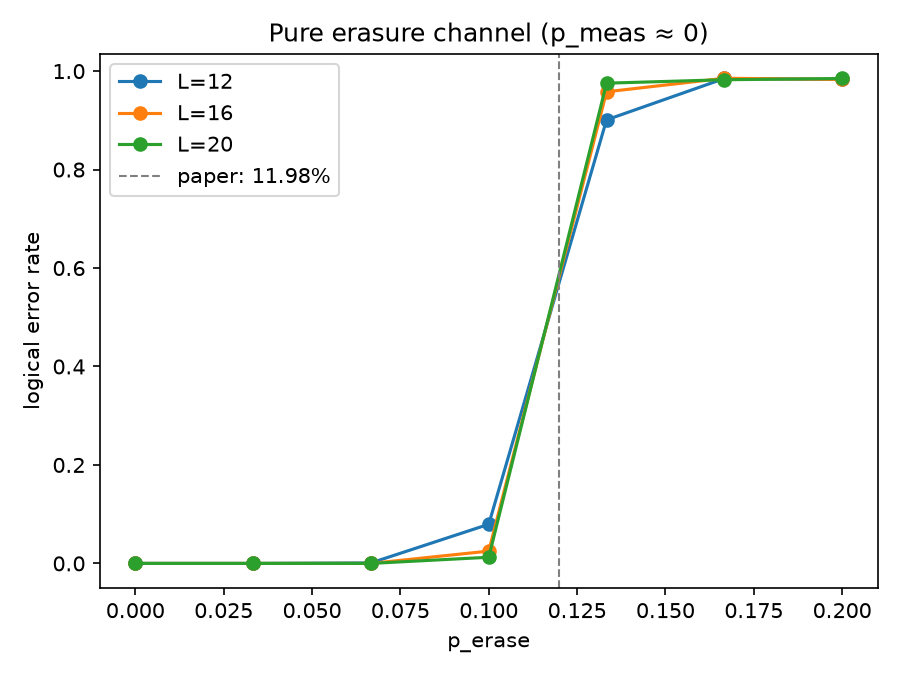

In [ ]:
plt.figure(figsize=(6, 4))
for L in Ls:
    plt.plot(p_eras, rows[L], "o-", label=f"L = {L}")
plt.axvline(0.1198, ls="--", c="grey", lw=1, label="paper: 11.98%")
plt.xlabel("erasure probability $p_{erase}$  (p_meas ≈ 0)")
plt.ylabel("logical error rate")
plt.title("6-ring FBQC, pure heralded-erasure channel")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Refined erasure threshold (denser sampling near the transition)

The plot above is a bit rough right at the transition, since the original sweep only had
7 points spread across the whole 0-0.2 range. Adding 8 more points densely packed into
0.075-0.15 (skipping `p_erase=0.1` and `0.1333`, already computed above) and fitting a
logistic curve `rate = 1 / (1 + exp(-k*(p - p0)))` per `L` gives a much smoother picture
of where each `L`'s threshold actually sits — and lets `p0` be read off directly instead
of eyeballed.

In [ ]:
from scipy.optimize import curve_fit

def sigmoid(p, p0, k):
    return 1.0 / (1.0 + np.exp(-k * (p - p0)))

# denser sampling right where the curve was roughest, skipping points already computed above
extra_p_eras = [p for p in np.linspace(0.075, 0.15, 10)
                if not any(abs(p - q) < 1e-9 for q in (0.1, 0.13333333333333333))]
extra_rows = {L: erasure_only_sweep(L, p_meas_eps, extra_p_eras, shots=2000, seed=3, n_workers=4)
              for L in Ls}

combined = {}
for L in Ls:
    pts = dict(zip(p_eras, rows[L]))
    pts.update(dict(zip(extra_p_eras, extra_rows[L])))
    ps = np.array(sorted(pts))
    combined[L] = (ps, np.array([pts[p] for p in ps]))

fits = {}
for L in Ls:
    ps, rr = combined[L]
    popt, _ = curve_fit(sigmoid, ps, rr, p0=[0.11, 80], maxfev=20000)
    fits[L] = popt
    print(f"L={L}: fitted threshold p0={popt[0]:.4f}, steepness k={popt[1]:.1f}")

L=12: fitted threshold p0=0.1182, steepness k=146.3
L=16: fitted threshold p0=0.1191, steepness k=190.8
L=20: fitted threshold p0=0.1190, steepness k=261.6


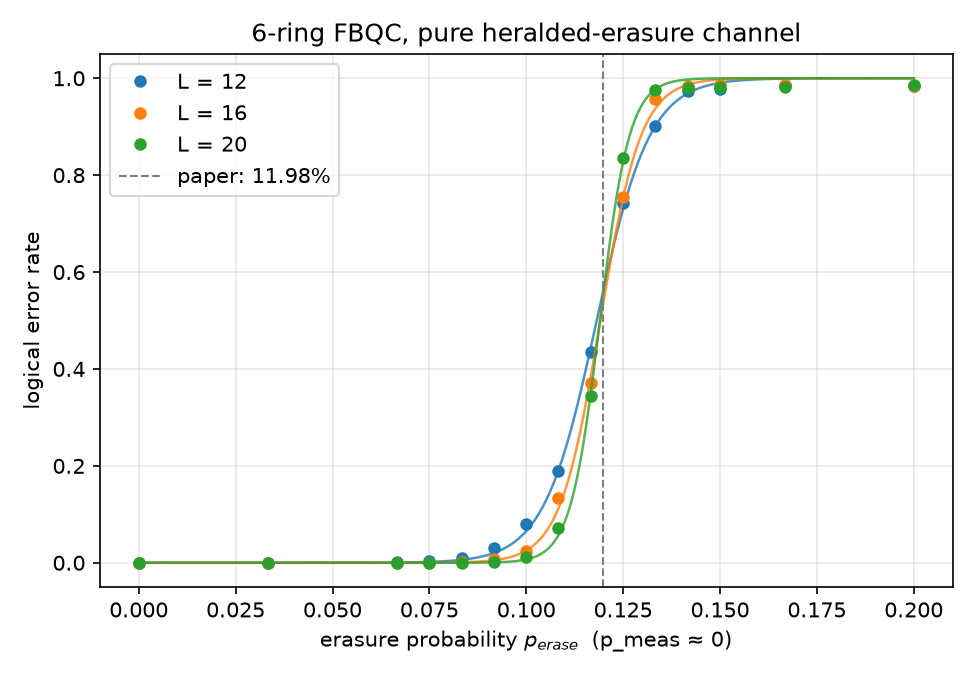

In [ ]:
plt.figure(figsize=(6.5, 4.5))
p_fine = np.linspace(0.0, 0.2, 400)
for L in Ls:
    ps, rr = combined[L]
    line, = plt.plot(ps, rr, "o", ms=5, label=f"L = {L}")
    plt.plot(p_fine, sigmoid(p_fine, *fits[L]), "-", lw=1.2, alpha=0.8, color=line.get_color())
plt.axvline(0.1198, ls="--", c="grey", lw=1, label="paper: 11.98%")
plt.xlabel("erasure probability $p_{erase}$  (p_meas ≈ 0)")
plt.ylabel("logical error rate")
plt.title("6-ring FBQC, pure heralded-erasure channel")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Threshold estimate: naive crossing + finite-size scaling

Same recipe as the measurement-noise section above (and `Hexagon_fbqc_walkthrough.ipynb`
§7): naive pairwise-crossing extrapolation for an approximate $p_c$, then more points
densely sampled around it, fit globally for an analytic $p_c$.

The sweeps above (`Ls=[12,16,20]`, plus the sigmoid-fit refinement) already hint at a
crossing near 12%, but `L=20` pays a steep per-shot decode cost right at the transition
-- the `L=20, p_erase=0.1667` point above took **over an hour** to decode. This section
uses `L = 6, 8, 10, 12, 16` (5 sizes -> 4 crossings): `L=16` is included on the coarse
9-point grid (checked directly: ~10s/point away from the transition, ~53s/point right at
it -- both fine as one-off costs), but is left out of the 10-point dense refinement below
it, since that would repeat the expensive near-transition points many more times. `L=6,8,
10,12` get the full dense treatment. This is the same size/time tradeoff called out above
for `L=20`, just drawn at a different line -- one extra size, not the full refinement.

In [ ]:
def erasure_only_sweep_thr(L, p_meas_eps, p_eras, shots=2000, Lk=None, seed=0, n_workers=4):
    """Same recipe as erasure_only_sweep above: sample the circuit once, reuse it
    across every p_erase value, decode with the forked-worker parallel decoder."""
    net = Net(L, Lk)
    st = get_outcome_matching(L, net.Lk, p_meas_eps)
    checks, logs, nmeas = st['checks'], st['logs'], st['nmeas']
    circuit, _, nmeas_actual = build(net, p_meas_eps)
    assert nmeas_actual == nmeas
    raw_bits = circuit.compile_sampler(seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)

    rates = []
    for j, pe in enumerate(p_eras):
        rng = np.random.default_rng((seed, L, j))
        erased_mask = rng.random(raw_bits.shape) < pe
        replacement_bits = rng.integers(0, 2, size=raw_bits.shape, dtype=np.uint8)
        outcomes = np.where(erased_mask, replacement_bits, raw_bits)
        dets = rows_to_parities(outcomes, checks)
        obs = rows_to_parities(outcomes, logs)
        pred = decode_with_erasure_parallel(dets, st['matcher'], st['outcome_edge'], st['weight'],
                                             len(logs), erased_mask, n_workers=n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / shots)
    return rates

Ls_ethr = [6, 8, 10, 12, 16]
p_meas_eps_ethr = 1e-9
shots_ethr = 2000
p_eras_ethr_coarse = np.linspace(0.04, 0.20, 9)

# data_ethr[L][p] = P_fail. A plain dict-of-dicts rather than a rectangular
# {p: [rate per L]} table, since L=16 only ever gets the coarse points below --
# every lookup goes through this and never assumes every L has every p.
data_ethr = {L: {} for L in Ls_ethr}

print(f"{'p_erase':>8} " + " ".join(f"{'L='+str(L):>9}" for L in Ls_ethr))
cols_ethr = {L: erasure_only_sweep_thr(L, p_meas_eps_ethr, p_eras_ethr_coarse, shots=shots_ethr, seed=21)
             for L in Ls_ethr}
for j, p in enumerate(p_eras_ethr_coarse):
    for L in Ls_ethr:
        data_ethr[L][p] = cols_ethr[L][j]
    print(f"{p:>8.4f} " + " ".join(f"{data_ethr[L][p]:>9.4f}" for L in Ls_ethr), flush=True)

 p_erase       L=6       L=8      L=10      L=12      L=16
  [erasure graph L=6,Lk=6,p_meas=1e-09: 1296 edges (one per outcome)]
  [erasure graph L=8,Lk=8,p_meas=1e-09: 3072 edges (one per outcome)]
  [erasure graph L=10,Lk=10,p_meas=1e-09: 6000 edges (one per outcome)]
  [erasure graph L=12,Lk=12,p_meas=1e-09: 10368 edges (one per outcome)]
  [erasure graph L=16,Lk=16,p_meas=1e-09: 24576 edges (one per outcome)]
  0.0400    0.0070    0.0000    0.0000    0.0000    0.0000
  0.0600    0.0270    0.0085    0.0015    0.0000    0.0005
  0.0800    0.0935    0.0350    0.0190    0.0085    0.0020
  0.1000    0.2505    0.1770    0.1205    0.0800    0.0270
  0.1200    0.5505    0.5510    0.5455    0.5510    0.5330
  0.1400    0.8185    0.8905    0.9290    0.9650    0.9790
  0.1600    0.9425    0.9755    0.9840    0.9860    0.9840
  0.1800    0.9770    0.9870    0.9840    0.9780    0.9835
  0.2000    0.9810    0.9855    0.9865    0.9835    0.9875


Naive crossing on the coarse grid gives the *approximate* threshold below. The next
cell adds 10 more points concentrated around that estimate before the global fit --
for `L = 6, 8, 10, 12` only; see the note above on why `L=16` sits out this part.

In [ ]:
# common_grid: the p values present for BOTH L1 and L2 -- exact-match
# intersection, safe since every finer grid below is built by literally
# reusing these float values (np.union1d), never recomputing them.
def common_grid(L1, L2):
    return np.intersect1d(np.array(sorted(data_ethr[L1])), np.array(sorted(data_ethr[L2])))

def crossing_for_pair(L1, L2):
    ps = common_grid(L1, L2)
    r1 = [data_ethr[L1][p] for p in ps]
    r2 = [data_ethr[L2][p] for p in ps]
    return find_crossing(ps, r1, r2)

print("Pairwise crossings (coarse grid):")
xs_ethr0, ps_star_ethr0 = [], []
for L1, L2 in zip(Ls_ethr[:-1], Ls_ethr[1:]):
    xc = crossing_for_pair(L1, L2)
    if xc is not None:
        xs_ethr0.append(0.5 * (1.0 / L1 + 1.0 / L2)); ps_star_ethr0.append(xc)
        print(f"  L={L1} x L={L2}: p* = {xc:.4f}")
    else:
        print(f"  L={L1} x L={L2}: no crossing found")

xs_ethr0, ps_star_ethr0 = np.array(xs_ethr0), np.array(ps_star_ethr0)
if len(xs_ethr0) >= 2:
    c0_ethr, p_c_approx_ethr = np.polyfit(xs_ethr0, ps_star_ethr0, 1)
elif len(xs_ethr0) == 1:
    p_c_approx_ethr = float(ps_star_ethr0[0])
else:
    p_c_approx_ethr = float(np.mean(p_eras_ethr_coarse))
    print(f"(no pairwise crossing found on the coarse grid -- falling back to the "
          f"grid midpoint, {p_c_approx_ethr:.4f}, as the search centre)")
print(f"\nApproximate threshold (naive crossing extrapolation): p_c ~= {p_c_approx_ethr:.4f}  ({p_c_approx_ethr*100:.2f}%)")

Pairwise crossings (coarse grid):
  L=6 x L=8: p* = 0.1199
  L=8 x L=10: p* = 0.1225
  L=10 x L=12: p* = 0.1176
  L=12 x L=16: p* = 0.1313

Approximate threshold (naive crossing extrapolation): p_c ~= 0.1345  (13.45%)


In [ ]:
Ls_ethr_dense = [L for L in Ls_ethr if L != 16]
window_ethr = 0.025
p_eras_ethr_fine = np.linspace(p_c_approx_ethr - window_ethr, p_c_approx_ethr + window_ethr, 10)

missing_ethr = {L: [p for p in p_eras_ethr_fine if p not in data_ethr[L]] for L in Ls_ethr_dense}
print(f"added up to {len(p_eras_ethr_fine)} points around p_c~={p_c_approx_ethr:.4f} for L in {Ls_ethr_dense}\n")
for L in Ls_ethr_dense:
    if not missing_ethr[L]:
        continue
    vals = erasure_only_sweep_thr(L, p_meas_eps_ethr, missing_ethr[L], shots=shots_ethr, seed=21)
    for p, v in zip(missing_ethr[L], vals):
        data_ethr[L][p] = v

for p in sorted(set(p_eras_ethr_coarse) | set(p_eras_ethr_fine)):
    row = "  ".join(f"{data_ethr[L][p]:>9.4f}" if p in data_ethr[L] else f"{'--':>9}" for L in Ls_ethr)
    print(f"{p:>8.4f}  " + row, flush=True)

added up to 10 points around p_c~=0.1345 for L in [6, 8, 10, 12]

  [built L=6,Lk=6: outcomes=1296 checks=214 logicals=6]
  [erasure graph L=6,Lk=6,p_meas=1e-09: 1296 edges (one per outcome)]
  [built L=8,Lk=8: outcomes=3072 checks=510 logicals=6]
  [erasure graph L=8,Lk=8,p_meas=1e-09: 3072 edges (one per outcome)]
  [built L=10,Lk=10: outcomes=6000 checks=998 logicals=6]
  [erasure graph L=10,Lk=10,p_meas=1e-09: 6000 edges (one per outcome)]
  [built L=12,Lk=12: outcomes=10368 checks=1726 logicals=6]
  [erasure graph L=12,Lk=12,p_meas=1e-09: 10368 edges (one per outcome)]
  0.0400     0.0070     0.0000     0.0000     0.0000     0.0000
  0.0600     0.0270     0.0085     0.0015     0.0000     0.0005
  0.0800     0.0935     0.0350     0.0190     0.0085     0.0020
  0.1000     0.2505     0.1770     0.1205     0.0800     0.0270
  0.1095     0.3825     0.3265     0.2680     0.2075         --
  0.1151     0.4610     0.4460     0.3975     0.3945         --
  0.1200     0.5505     0.5510     

wrote sixring_erasure_threshold/results.csv
Monotonicity check (P_fail should be non-decreasing in p_erase for each L):
  L=6: 1 decreasing step(s) out of 18  <-- within shot noise
  L=8: 3 decreasing step(s) out of 18  <-- within shot noise
  L=10: 0 decreasing step(s) out of 18
  L=12: 3 decreasing step(s) out of 18  <-- within shot noise
  L=16: 1 decreasing step(s) out of 8  <-- within shot noise


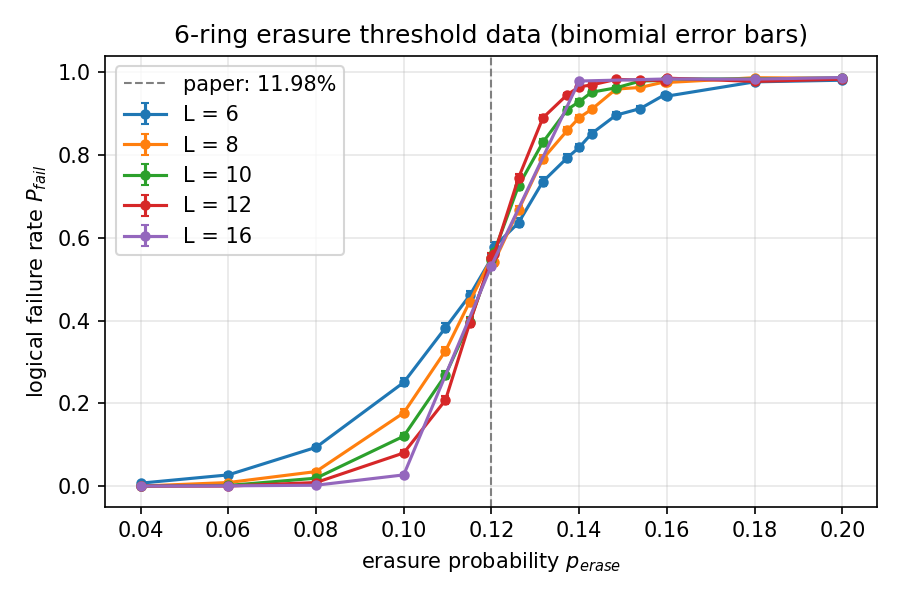

In [ ]:
import csv
import os

out_dir_ethr = "sixring_erasure_threshold"
os.makedirs(out_dir_ethr, exist_ok=True)

csv_path_ethr = os.path.join(out_dir_ethr, "results.csv")
with open(csv_path_ethr, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["p", "L", "P_fail", "n_shots"])
    for L in Ls_ethr:
        for p in sorted(data_ethr[L]):
            writer.writerow([p, L, data_ethr[L][p], shots_ethr])
print(f"wrote {csv_path_ethr}")

p_all_ethr = np.array([p for L in Ls_ethr for p in data_ethr[L]])
L_all_ethr = np.array([L for L in Ls_ethr for p in data_ethr[L]], dtype=float)
P_all_ethr = np.array([data_ethr[L][p] for L in Ls_ethr for p in data_ethr[L]])
sigma_all_ethr = np.clip(np.sqrt(P_all_ethr * (1 - P_all_ethr) / shots_ethr), 1e-4, None)

plt.figure(figsize=(6, 4))
for L in Ls_ethr:
    ps = np.array(sorted(data_ethr[L]))
    PP = np.array([data_ethr[L][p] for p in ps])
    ss = np.clip(np.sqrt(PP * (1 - PP) / shots_ethr), 1e-4, None)
    plt.errorbar(ps, PP, yerr=ss, fmt="o-", ms=4, capsize=2, label=f"L = {L}")
plt.axvline(0.1198, ls="--", c="grey", lw=1, label="paper: 11.98%")
plt.xlabel("erasure probability $p_{erase}$")
plt.ylabel("logical failure rate $P_{fail}$")
plt.title("6-ring erasure threshold data (binomial error bars)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_ethr, "threshold_data.png"), dpi=150)
plt.show()

print("Monotonicity check (P_fail should be non-decreasing in p_erase for each L):")
for L in Ls_ethr:
    ps = np.array(sorted(data_ethr[L]))
    PP = np.array([data_ethr[L][p] for p in ps])
    diffs = np.diff(PP)
    n_viol = int(np.sum(diffs < -1e-9))
    flag = "  <-- within shot noise" if n_viol else ""
    print(f"  L={L}: {n_viol} decreasing step(s) out of {len(diffs)}{flag}")

Pairwise crossings (refined grid):
  L=6 x L=8: p* = 0.1198
  L=8 x L=10: p* = 0.1201
  L=10 x L=12: p* = 0.1168
  L=12 x L=16: p* = 0.1313

Naive crossing extrapolation (linear in 1/L_avg): p_c = 0.1339 +/- 0.0130


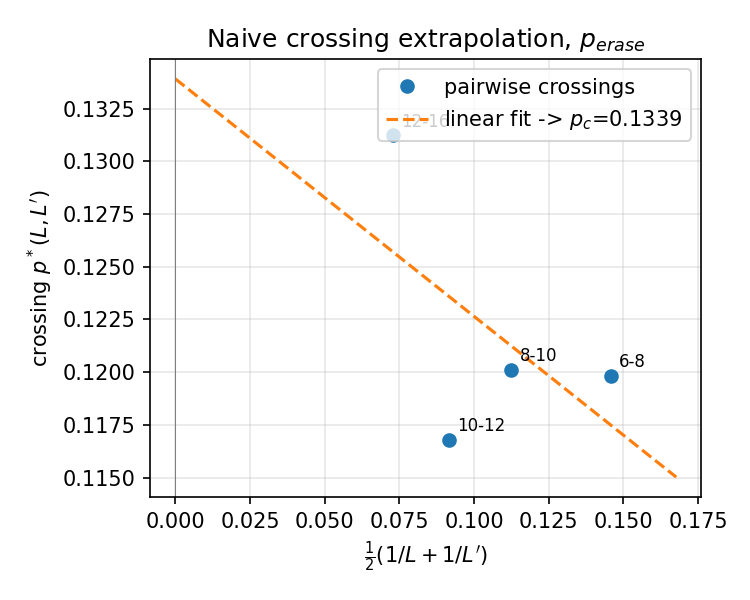

In [ ]:
print("Pairwise crossings (refined grid):")
xs_ethr, ps_star_ethr, pair_labels_ethr = [], [], []
for L1, L2 in zip(Ls_ethr[:-1], Ls_ethr[1:]):
    # crossing_for_pair intersects each pair's own available p's, so (12, 16)
    # automatically falls back to the coarse-only common grid, while pairs
    # among 6/8/10/12 pick up the full dense grid -- no separate branch needed.
    xc = crossing_for_pair(L1, L2)
    if xc is not None:
        x = 0.5 * (1.0 / L1 + 1.0 / L2)
        xs_ethr.append(x); ps_star_ethr.append(xc); pair_labels_ethr.append(f"{L1}-{L2}")
        print(f"  L={L1} x L={L2}: p* = {xc:.4f}")
    else:
        print(f"  L={L1} x L={L2}: no crossing found")

xs_ethr, ps_star_ethr = np.array(xs_ethr), np.array(ps_star_ethr)
if len(xs_ethr) > 2:
    (c_slope_ethr, p_c_naive_ethr), cov_naive_ethr = np.polyfit(xs_ethr, ps_star_ethr, 1, cov=True)
    p_c_naive_ethr_err = np.sqrt(cov_naive_ethr[1, 1])
elif len(xs_ethr) == 2:
    c_slope_ethr = (ps_star_ethr[-1] - ps_star_ethr[0]) / (xs_ethr[-1] - xs_ethr[0])
    p_c_naive_ethr = ps_star_ethr[0] - c_slope_ethr * xs_ethr[0]
    p_c_naive_ethr_err = np.nan
    print("(only 2 crossings available -- extrapolated intercept has no meaningful uncertainty)")
else:
    c_slope_ethr = 0.0
    p_c_naive_ethr = float(ps_star_ethr[0]) if len(ps_star_ethr) else float(np.mean(p_eras_ethr))
    p_c_naive_ethr_err = np.nan
    print("(fewer than 2 crossings on the refined grid -- naive extrapolation is not meaningful)")
dof_ethr = len(xs_ethr) - 2
print(f"\nNaive crossing extrapolation (linear in 1/L_avg): p_c = {p_c_naive_ethr:.4f} +/- {p_c_naive_ethr_err:.4f}")
if dof_ethr <= 1:
    print(f"(note: only {dof_ethr} residual dof -- the quoted uncertainty is not robust)")

plt.figure(figsize=(5, 4))
plt.plot(xs_ethr, ps_star_ethr, "o", label="pairwise crossings")
for x, y, lab in zip(xs_ethr, ps_star_ethr, pair_labels_ethr):
    plt.annotate(lab, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=8)
xx = np.linspace(0, xs_ethr.max() * 1.15, 50)
plt.plot(xx, c_slope_ethr * xx + p_c_naive_ethr, "--", label=f"linear fit -> $p_c$={p_c_naive_ethr:.4f}")
plt.axvline(0, c="grey", lw=0.5)
plt.xlabel(r"$\frac{1}{2}(1/L + 1/L')$")
plt.ylabel(r"crossing $p^*(L,L')$")
plt.title("Naive crossing extrapolation, $p_{erase}$")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_ethr, "threshold_naive_crossing.png"), dpi=150)
plt.show()

In [ ]:
from scipy.special import erf
from scipy.optimize import curve_fit

def model_quad_ethr(X, p_c, nu, A0, A1, A2):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_linear_ethr(X, p_c, nu, A0, A1):
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A1 * x + A0
    return 0.5 * (1 - erf(G / np.sqrt(2)))

def model_baseline_ethr(X, p_c, w):
    p, L = X
    z = (p - p_c) / w
    return 0.5 * (1 - erf(z / np.sqrt(2)))

X_ethr = np.vstack([p_all_ethr, L_all_ethr])
p_c0_ethr = float(np.clip(p_c_naive_ethr, p_all_ethr.min(), p_all_ethr.max()))

bounds_quad_ethr = ([p_all_ethr.min(), 0.05, -5, -50, -5], [p_all_ethr.max(), 10, 5, 0, 5])
bounds_lin_ethr  = ([p_all_ethr.min(), 0.05, -5, -50], [p_all_ethr.max(), 10, 5, 0])
bounds_base_ethr = ([p_all_ethr.min(), 1e-4], [p_all_ethr.max(), 1.0])

popt_quad_ethr, pcov_quad_ethr = curve_fit(model_quad_ethr, X_ethr, P_all_ethr,
                                            p0=[p_c0_ethr, 1.0, 0.0, -5.0, 0.0],
                                            sigma=sigma_all_ethr, absolute_sigma=True,
                                            bounds=bounds_quad_ethr, maxfev=30000)
perr_quad_ethr = np.sqrt(np.diag(pcov_quad_ethr))

popt_lin_ethr, pcov_lin_ethr = curve_fit(model_linear_ethr, X_ethr, P_all_ethr,
                                          p0=[p_c0_ethr, 1.0, 0.0, -5.0],
                                          sigma=sigma_all_ethr, absolute_sigma=True,
                                          bounds=bounds_lin_ethr, maxfev=30000)
perr_lin_ethr = np.sqrt(np.diag(pcov_lin_ethr))

popt_base_ethr, pcov_base_ethr = curve_fit(model_baseline_ethr, X_ethr, P_all_ethr,
                                            p0=[p_c0_ethr, 0.02], sigma=sigma_all_ethr,
                                            absolute_sigma=True, bounds=bounds_base_ethr, maxfev=30000)

print("Quadratic-erf fit (5 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_ethr, perr_quad_ethr):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")
print("Linear-erf fit (4 params):")
for name, v, e in zip(["p_c", "nu", "A0", "A1"], popt_lin_ethr, perr_lin_ethr):
    print(f"  {name} = {v:.5f} +/- {e:.5f}")

for name, v, lo, hi in zip(["p_c", "nu", "A0", "A1", "A2"], popt_quad_ethr,
                            bounds_quad_ethr[0], bounds_quad_ethr[1]):
    if np.isclose(v, lo, rtol=1e-6) or np.isclose(v, hi, rtol=1e-6):
        print(f"  WARNING: quadratic fit parameter {name} = {v:.5f} is pinned to its bound")

Quadratic-erf fit (5 params):
  p_c = 0.12025 +/- 0.00026
  nu = 0.91622 +/- 0.01673
  A0 = -0.14804 +/- 0.01575
  A1 = -5.31534 +/- 0.23152
  A2 = -0.02561 +/- 0.13174
Linear-erf fit (4 params):
  p_c = 0.12025 +/- 0.00026
  nu = 0.91629 +/- 0.01674
  A0 = -0.14844 +/- 0.01561
  A1 = -5.31723 +/- 0.23182


In [ ]:
def fit_stats_ethr(model, popt, k):
    pred = model(X_ethr, *popt)
    resid = P_all_ethr - pred
    rss = np.sum(resid**2)
    chi2 = np.sum((resid / sigma_all_ethr) ** 2)
    n = len(P_all_ethr)
    return rss, chi2, chi2 + 2 * k, chi2 + k * np.log(n)

stats_ethr = {
    "quadratic-erf (5p)": fit_stats_ethr(model_quad_ethr, popt_quad_ethr, 5),
    "linear-erf (4p)": fit_stats_ethr(model_linear_ethr, popt_lin_ethr, 4),
    "baseline, no-L (2p)": fit_stats_ethr(model_baseline_ethr, popt_base_ethr, 2),
}
print(f"{'model':22} {'RSS':>12} {'chi2':>12} {'AIC':>12} {'BIC':>12}")
for name, (rss, chi2, aic, bic) in stats_ethr.items():
    print(f"{name:22} {rss:12.6f} {chi2:12.3f} {aic:12.3f} {bic:12.3f}")

model                           RSS         chi2          AIC          BIC
quadratic-erf (5p)         0.014364      747.738      757.738      769.951
linear-erf (4p)            0.014393      747.753      755.753      765.524
baseline, no-L (2p)       45.997536 103124582.608 103124586.608 103124591.494


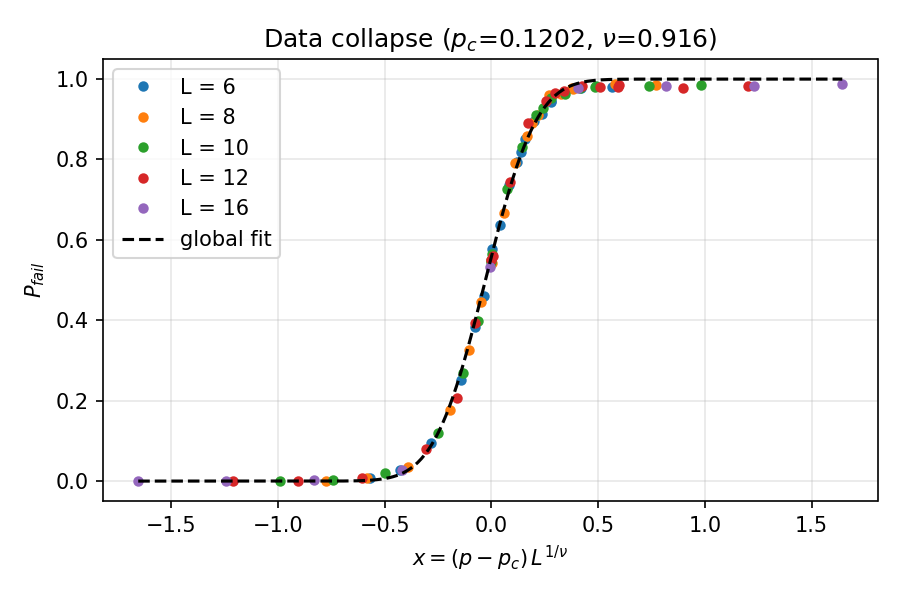

In [ ]:
p_c_fit_ethr, nu_fit_ethr = popt_quad_ethr[0], popt_quad_ethr[1]
A0f_ethr, A1f_ethr, A2f_ethr = popt_quad_ethr[2], popt_quad_ethr[3], popt_quad_ethr[4]

plt.figure(figsize=(6, 4))
for L in Ls_ethr:
    idx = L_all_ethr == L
    order = np.argsort(p_all_ethr[idx])
    pp, PP = p_all_ethr[idx][order], P_all_ethr[idx][order]
    x = (pp - p_c_fit_ethr) * L ** (1.0 / nu_fit_ethr)
    plt.plot(x, PP, "o", ms=4, label=f"L = {L}")

x_all_ethr = (p_all_ethr - p_c_fit_ethr) * L_all_ethr ** (1.0 / nu_fit_ethr)
xx = np.linspace(x_all_ethr.min(), x_all_ethr.max(), 200)
Gxx = A2f_ethr * xx**2 + A1f_ethr * xx + A0f_ethr
plt.plot(xx, 0.5 * (1 - erf(Gxx / np.sqrt(2))), "k--", lw=1.5, label="global fit")
plt.xlabel(r"$x = (p - p_c)\, L^{1/\nu}$")
plt.ylabel("$P_{fail}$")
plt.title(f"Data collapse ($p_c$={p_c_fit_ethr:.4f}, $\\nu$={nu_fit_ethr:.3f})")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(os.path.join(out_dir_ethr, "threshold_data_collapse.png"), dpi=150)
plt.show()

In [ ]:
p_c_global_ethr, p_c_global_ethr_err = popt_quad_ethr[0], perr_quad_ethr[0]

print("=" * 60)
print("ERASURE THRESHOLD ESTIMATE SUMMARY")
print("=" * 60)
if np.isfinite(p_c_naive_ethr_err):
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_ethr:.4f} +/- {p_c_naive_ethr_err:.4f}")
else:
    print(f"Naive crossing extrapolation:  p_c = {p_c_naive_ethr:.4f}  (uncertainty undefined -- "
          f"too few crossings, illustrative only)")
print(f"Global quadratic-erf FSS fit:  p_c = {p_c_global_ethr:.5f} +/- {p_c_global_ethr_err:.5f}"
      f"  (nu = {nu_fit_ethr:.3f} +/- {perr_quad_ethr[1]:.3f})")

diff_ethr = abs(p_c_naive_ethr - p_c_global_ethr)
print(f"\nDifference from naive point estimate: {diff_ethr:.4f}", end="")
if np.isfinite(p_c_naive_ethr_err):
    combined_sigma_ethr = np.sqrt(p_c_naive_ethr_err**2 + p_c_global_ethr_err**2)
    n_sigma_ethr = diff_ethr / combined_sigma_ethr if combined_sigma_ethr > 0 else np.inf
    print(f"  ({n_sigma_ethr:.2f} sigma)")
else:
    n_sigma_ethr = np.nan
    print("  (sigma undefined, see above)")
if not np.isfinite(n_sigma_ethr):
    pass
elif n_sigma_ethr > 2:
    print("-> naive and global estimates disagree by >2 sigma; treat p_c with caution.")
elif n_sigma_ethr > 1:
    print("-> mild (1-2 sigma) tension between the two estimates.")
else:
    print("-> naive and global estimates agree within 1 sigma.")

print("\nFor reference: paper (Bartolucci et al., arXiv:2101.09310) reports 11.98%.")
print(f"\nREPORTED THRESHOLD: p_c = {p_c_global_ethr:.5f} +/- {p_c_global_ethr_err:.5f}"
      f"  ({p_c_global_ethr * 100:.3f}% +/- {p_c_global_ethr_err * 100:.3f}%)")

ERASURE THRESHOLD ESTIMATE SUMMARY
Naive crossing extrapolation:  p_c = 0.1339 +/- 0.0130
Global quadratic-erf FSS fit:  p_c = 0.12025 +/- 0.00026  (nu = 0.916 +/- 0.017)

Difference from naive point estimate: 0.0137  (1.05 sigma)
-> mild (1-2 sigma) tension between the two estimates.

For reference: paper (Bartolucci et al., arXiv:2101.09310) reports 11.98%.

REPORTED THRESHOLD: p_c = 0.12025 +/- 0.00026  (12.025% +/- 0.026%)


---
## 8. Threshold from a global finite-size-scaling fit, as one function

§5 and §7 each fit their threshold with the same recipe, written out inline twice. It
is a global quadratic-erf finite-size-scaling fit, followed by a data collapse.
`fss_threshold` packages that recipe so it can be applied to any set of curves (§9
uses it once per `δ`).

**Input.** The curves `{L: (ps, P_fail)}` or `{L: {p: P_fail}}`, plus the shots per
point. Each `L` may have its own `p` grid, as §7's `L = 16` does. All points are fit at
once to

$$P_{fail}(p, L) = p_{max}\,\tfrac12\left[1 - \mathrm{erf}\!\left(G(x)/\sqrt2\right)\right],
\qquad G = A_0 + A_1 x + A_2 x^2,\qquad x = (p - p_c)\,L^{1/\nu}.$$

Each point is weighted by its binomial error, as in §5/§7. `model="linear"` drops
`A_2`. `p_max` (default 1, as in §5/§7) is the failure rate the curves saturate at.
§9's `δ = 1` curves level off at 15/16 because two of the six logicals can never fail
there.

**Output.** A dict with `p_c`, `nu`, their errors, `chi2_dof` and every fit parameter.
By default it also draws two panels: the data with the fitted curve for each `L`, and
the data collapse onto one curve.

**Two error bars.** `p_c_err` is the absolute-sigma error §5/§7 quote. When
`chi2/dof > 1`, the model does not describe the data to within shot noise, and that
error is too small by a factor `sqrt(chi2/dof)`. `p_c_err_scaled` applies that
factor, and it is the one to quote. Neither error accounts for the points on one
curve being correlated: §9 reuses one noiseless sample across `p`.

Starting point: by default `p_c` starts at the mean of the adjacent-size crossings
(§5's `find_crossing`). `nu` is tried at 0.7, 1 and 1.5, and the fit with the lowest
chi2 is kept. The bounds are §5's.

In [ ]:
import matplotlib.pyplot as plt
from scipy.special import erf
from scipy.optimize import curve_fit


def fss_model(X, p_c, nu, A0, A1, A2=0.0, p_max=1.0):
    """P_fail(p, L) = p_max (1/2)[1 - erf(G(x)/sqrt 2)],  G = A0 + A1 x + A2 x^2,
    x = (p - p_c) L^(1/nu). A2 = 0 is §5/§7's linear-erf model."""
    p, L = X
    x = (p - p_c) * L ** (1.0 / nu)
    G = A2 * x**2 + A1 * x + A0
    return p_max * 0.5 * (1 - erf(G / np.sqrt(2)))


def _as_points(curves, shots):
    """{L: (ps, rates)} or {L: {p: rate}} -> flat arrays p, L, P, n (one entry per point)."""
    p_all, L_all, P_all, n_all = [], [], [], []
    for L in sorted(curves):
        c = curves[L]
        ps, rates = (list(c.keys()), list(c.values())) if isinstance(c, dict) else c
        n = shots[L] if isinstance(shots, dict) else shots
        p_all += list(ps); L_all += [L] * len(ps); P_all += list(rates); n_all += [n] * len(ps)
    return (np.array(p_all, dtype=float), np.array(L_all, dtype=float),
            np.array(P_all, dtype=float), np.array(n_all, dtype=float))


def fss_threshold(curves, shots, model="quadratic", p_max=1.0, p_c0=None,
                  plot=True, title="", xlabel="$p$", save=None):
    """Global finite-size-scaling fit and data collapse (§5/§7's recipe) for any set of curves.

    curves : {L: (ps, P_fail)} or {L: {p: P_fail}}. Each L may have its own p grid.
    shots  : shots per point, an int or {L: int}. Sets the binomial error bars
             sigma = sqrt(P(1-P)/shots), floored at 1e-4 as in §5/§7.
    model  : "quadratic" (5 parameters, §5/§7's reported fit) or "linear" (A2 = 0).
    p_max  : the failure rate the curves saturate at. Leave it at 1 to match §5/§7.
             Use it when some logicals can never fail (e.g. 15/16 at §9's δ = 1).
    p_c0   : starting guess for p_c. By default, the mean of the pairwise crossings of
             adjacent sizes (§5's find_crossing), else the middle of the p range.

    Returns a dict:
      p_c, nu, popt, chi2, dof, chi2_dof,
      p_c_err, nu_err      -- absolute-sigma errors (the ones §5/§7 quote),
      p_c_err_scaled       -- p_c_err x sqrt(chi2/dof) when chi2/dof > 1. This is the
                              honest error when the model does not fit to within shot noise.
    The fit starts from a few values of nu and keeps the lowest chi2."""
    p, L, P, n = _as_points(curves, shots)
    sigma = np.clip(np.sqrt(P * (1 - P) / n), 1e-4, None)
    sizes = sorted(set(L))
    quad = model == "quadratic"

    if p_c0 is None:
        cross = []
        for L1, L2 in zip(sizes[:-1], sizes[1:]):
            r1 = dict(zip(p[L == L1], P[L == L1])); r2 = dict(zip(p[L == L2], P[L == L2]))
            grid = sorted(set(r1) & set(r2))
            xc = find_crossing(grid, [r1[q] for q in grid], [r2[q] for q in grid]) if len(grid) > 1 else None
            if xc is not None:
                cross.append(xc)
        p_c0 = float(np.mean(cross)) if cross else 0.5 * (p.min() + p.max())
    p_c0 = float(np.clip(p_c0, p.min(), p.max()))

    f = (lambda X, p_c, nu, A0, A1, A2: fss_model(X, p_c, nu, A0, A1, A2, p_max)) if quad else \
        (lambda X, p_c, nu, A0, A1: fss_model(X, p_c, nu, A0, A1, 0.0, p_max))
    lo = [p.min(), 0.05, -20, -200] + ([-200] if quad else [])
    hi = [p.max(), 10, 20, 0] + ([200] if quad else [])
    best = None
    for nu0 in (0.7, 1.0, 1.5):
        try:
            popt, pcov = curve_fit(f, np.vstack([p, L]), P, p0=[p_c0, nu0, 0.0, -5.0] + ([0.0] if quad else []),
                                   sigma=sigma, absolute_sigma=True, bounds=(lo, hi), maxfev=30000)
        except RuntimeError:
            continue
        chi2 = float(np.sum(((P - f(np.vstack([p, L]), *popt)) / sigma) ** 2))
        if best is None or chi2 < best[2]:
            best = (popt, pcov, chi2)
    if best is None:
        raise RuntimeError("FSS fit did not converge from any starting point")
    popt, pcov, chi2 = best
    perr = np.sqrt(np.diag(pcov))
    dof = len(P) - len(popt)
    chi2_dof = chi2 / dof if dof > 0 else np.nan
    names = ["p_c", "nu", "A0", "A1", "A2"][:len(popt)]
    pinned = [nm for nm, v, a, b in zip(names, popt, lo, hi) if np.isclose(v, a, rtol=1e-6) or np.isclose(v, b, rtol=1e-6)]
    res = dict(p_c=popt[0], p_c_err=perr[0], nu=popt[1], nu_err=perr[1], popt=popt, perr=perr,
               chi2=chi2, dof=dof, chi2_dof=chi2_dof, pinned=pinned,
               p_c_err_scaled=perr[0] * np.sqrt(max(1.0, chi2_dof)) if dof > 0 else np.nan)

    if plot:
        fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.3))
        xx_all = (p - popt[0]) * L ** (1.0 / popt[1])
        for k, Lk in enumerate(sizes):                     # fixed colour per position in `sizes`
            m = L == Lk
            o = np.argsort(p[m])
            col, mk = f"C{k}", "osD^vP"[k % 6]
            ax0.errorbar(p[m][o], P[m][o], yerr=sigma[m][o], fmt=mk, ms=4, capsize=2, color=col, label=f"L = {Lk:g}")
            pf = np.linspace(p[m].min(), p[m].max(), 200)
            ax0.plot(pf, f(np.vstack([pf, np.full_like(pf, Lk)]), *popt), color=col, lw=1.2)
            ax1.plot(xx_all[m], P[m], mk, ms=4, color=col, label=f"L = {Lk:g}")
        xs = np.linspace(xx_all.min(), xx_all.max(), 300)
        G = popt[2] + popt[3] * xs + (popt[4] * xs**2 if quad else 0.0)
        ax1.plot(xs, p_max * 0.5 * (1 - erf(G / np.sqrt(2))), "k--", lw=1.5, label="global fit")
        ax0.axvline(popt[0], color="0.4", ls="--", lw=1)
        ax0.set_xlabel(xlabel); ax0.set_ylabel("logical failure rate $P_{fail}$")
        ax0.set_title(f"data and global fit ({model}-erf)", fontsize=10, loc="left")
        ax1.set_xlabel(r"$x = (p - p_c)\, L^{1/\nu}$"); ax1.set_ylabel("$P_{fail}$")
        ax1.set_title(f"collapse: $p_c$ = {popt[0]:.5f} ± {res['p_c_err_scaled']:.5f}, "
                      f"$\\nu$ = {popt[1]:.3f},  $\\chi^2$/dof = {chi2_dof:.2f}", fontsize=10, loc="left")
        for ax in (ax0, ax1):
            ax.grid(alpha=.3); ax.legend(fontsize=8, frameon=False)
        if title:
            fig.suptitle(title, fontsize=11)
        fig.tight_layout()
        if save:
            fig.savefig(save, dpi=150)
        plt.show()

    print(f"{title + ': ' if title else ''}p_c = {popt[0]:.5f} ± {perr[0]:.5f} (abs. sigma), "
          f"± {res['p_c_err_scaled']:.5f} (scaled by sqrt(chi2/dof))   nu = {popt[1]:.3f} ± {perr[1]:.3f}   "
          f"chi2/dof = {chi2_dof:.2f} ({len(P)} points, {len(sizes)} sizes)"
          + (f"   WARNING: pinned to bound: {pinned}" if pinned else ""))
    return res

### Check: reproduce §5 and §7

§5 and §7 saved their curves to `results.csv`. Fitting those saved curves with
`fss_threshold` should give back the thresholds those sections report. This cell needs
only the saved files, not §5's or §7's sweeps.

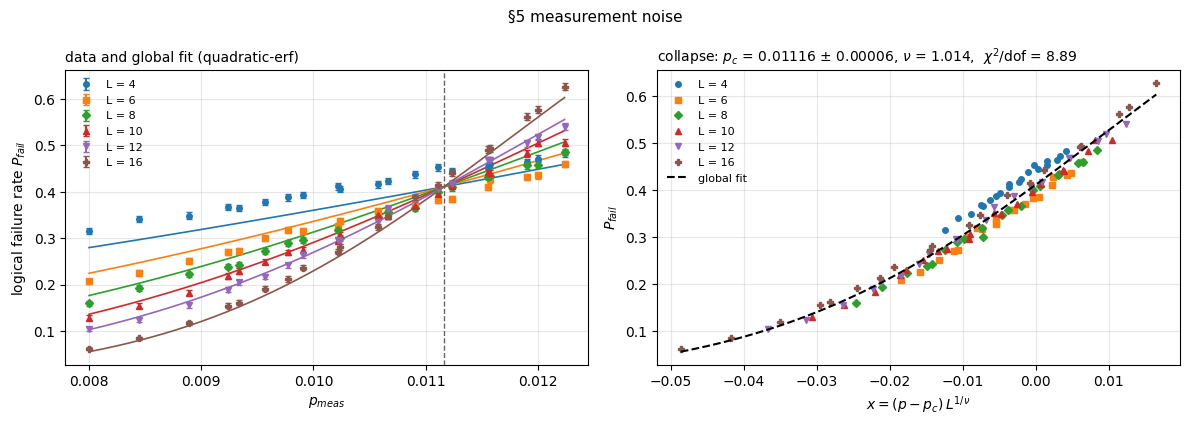

§5 measurement noise: p_c = 0.01116 ± 0.00002 (abs. sigma), ± 0.00006 (scaled by sqrt(chi2/dof))   nu = 1.014 ± 0.017   chi2/dof = 8.89 (120 points, 6 sizes)
   §5 measurement noise reported p_c = 0.01116, nu = 1.014:  reproduced



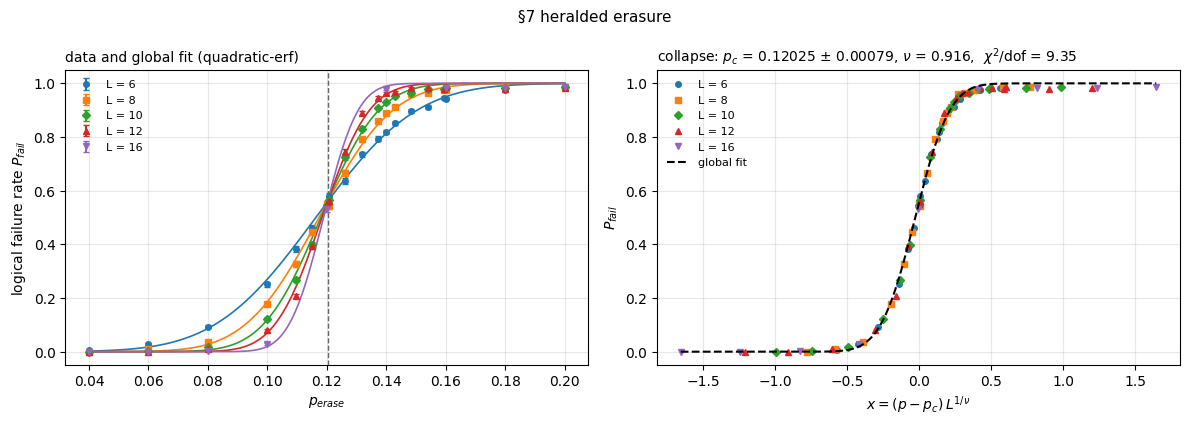

§7 heralded erasure: p_c = 0.12025 ± 0.00026 (abs. sigma), ± 0.00079 (scaled by sqrt(chi2/dof))   nu = 0.916 ± 0.017   chi2/dof = 9.35 (85 points, 5 sizes)
   §7 heralded erasure reported p_c = 0.12025, nu = 0.916:  reproduced



In [ ]:
import csv


def read_results_csv(path):
    """§5/§7's results.csv (columns p, L, P_fail, n_shots) -> ({L: {p: P_fail}}, {L: shots})."""
    curves, shots = {}, {}
    with open(path) as f:
        for r in csv.DictReader(f):
            L = int(r["L"])
            curves.setdefault(L, {})[float(r["p"])] = float(r["P_fail"])
            shots[L] = int(r["n_shots"])
    return curves, shots


# §5 and §7's reported quadratic-erf fits, to check the function reproduces them
for name, path, xlab, (pc_ref, nu_ref) in (
        ("§5 measurement noise", "sixring_measurement_threshold/results.csv", "$p_{meas}$", (0.01116, 1.014)),
        ("§7 heralded erasure", "sixring_erasure_threshold/results.csv", "$p_{erase}$", (0.12025, 0.916))):
    res = fss_threshold(*read_results_csv(path), title=name, xlabel=xlab)
    print(f"   {name} reported p_c = {pc_ref}, nu = {nu_ref}:  "
          f"{'reproduced' if abs(res['p_c'] - pc_ref) < 5e-5 and abs(res['nu'] - nu_ref) < 5e-3 else 'MISMATCH'}\n")

### Result

Both reported fits come back exactly:

| | `p_c` | `ν` | chi2/dof |
|---|---|---|---|
| §5, `p_meas`  | 1.116% | 1.014 | 8.9 |
| §7, `p_erase` | 12.025% | 0.916 | 9.4 |

§7 used tighter parameter bounds than §5. With §5's wider bounds the fit lands on the
same point, so the function can use one set of bounds for both.

**The errors §5 and §7 quote are too small, by a factor of about 3.** Both fits have
chi2/dof ≈ 9, so the absolute-sigma errors (±0.002 and ±0.026 points) understate the
uncertainty. The scaled errors are ±0.006 points for `p_meas` and ±0.08 points for
`p_erase`. §5's left panel shows where the misfit comes from: the `L = 4` points sit
well off their fitted curve. A single quadratic `G(x)` with no corrections to scaling
cannot describe `L = 4` together with the larger sizes.

---
## 9. Biased measurement error: threshold vs `δ`

§5 flips both outcomes of every fusion at the same rate `p`. Here a bias parameter
`δ` moves that noise between the two outcomes a fusion reports, keeping the total
fixed (the same model as `Hexagon_fbqc_walkthrough.ipynb` §11-§13):

| fusion outcome | flipped with probability |
|---|---|
| `X_a X_b` (1st record, §2) | `2 (1 - δ) p` |
| `Z_a Z_b` (2nd record, §2) | `2 δ p` |

So `δ = 0` flips only `XX` outcomes (at `2p`), `δ = 1` only `ZZ` outcomes, and
**`δ = 0.5` is exactly §5's model**, `p` on each outcome. For each `δ` the whole
`p_meas` sweep is redone and its threshold found, giving `p_th(δ)`. At `δ = 0.5` it
should reproduce §5's ≈ 1.1%.

### What each end of `δ` looks like to the decoder

Every outcome sits in exactly two checks, so it is one edge of the decoding graph. All
12 terms of a check (§4) are split evenly: 6 `XX` and 6 `ZZ`. The next cell keeps only
one kind of edge and looks at what is left, separately for the primal (X-check) and
dual (Z-check) graphs:

* **`XX` edges only (`δ = 0`).** Each sector is a connected **simple cubic lattice**,
  with one axis in time, `(0,0,1)`, and two in space, `(1,±1,0)`. This is the
  phenomenological toric-code problem with equal data and measurement error, whose
  MWPM threshold is about 2.9% per edge (Wang, Harrington & Preskill 2003; the
  hexagon notebook's §10 found 2.98% for the same problem). Here the per-edge rate is
  `2p`, so the **prediction is `p_th(0) ≈ 1.45-1.5%`**.
* **`ZZ` edges only (`δ = 1`).** The three directions `(1,1,-1)`, `(1,-1,1)`, `(2,0,0)`
  are linearly dependent (the third is the sum of the first two). So the graph
  **falls apart into `L` disconnected 2D triangular layers**, and the problem becomes
  `L` independent 2D matching problems with no "measurement-error" direction. Expect
  `p_th(1)` to be well above `p_th(0)`.

The hexagon code has no such split: there, both ends of `δ` stay 3D and come out
about equal (its §14b).

### Method

The same two-pass search as the hexagon notebook's §13, on this code:

* **Noise and decoder.** The noise follows the measured operator. A plain fusion
  reports `X_aX_b` first (§2), so the `XX` mask is every fusion's first record. The
  decoder is §7's one-edge-per-outcome matcher, with each edge reweighted to
  `log((1 - q)/q)` for its outcome's flip rate `q`. An outcome that never flips
  (`q = 0`, the two ends of `δ`) gets a large finite weight, because pymatching drops
  edges above its weight cap (§7).
* **Sampling.** One noiseless 20,000-shot sample per `L`. Flips are applied in
  post-processing, as in the hexagon notebook. The noiseless sample is reused across
  `p` and `δ`, so the points on one curve are correlated.
* **Sizes `L = 12, 16, 18`.** An earlier run at `L = 8, 12, 16` is reloaded alongside
  for comparison. It shares the noiseless samples at `L = 12` and `16`, so the two
  runs are not independent there. `L = 4` cannot be used at all, because §7's matcher
  needs `L ≥ 6`.
* **Pass 1, coarse:** 15 log-spaced `p` from 0.4% to 8% at the two smallest sizes.
  Their crossing is the centre for pass 2.
* **Pass 2, fine:** 11 points from 0.75x to 1.25x that centre, at all three sizes.
* **The threshold** is §8's global finite-size-scaling fit to each `δ`'s three fine
  curves (33 points), quoted with the scaled error. Adjacent-size crossings, from §5's
  `find_crossing`, are plotted as a cross-check.
* **`δ` grid:** 0 to 1 in steps of 1/8.

This section needs only the definition cells of §1-§5, §7 and §8, not any of their
sweeps. The `L = 12, 16, 18` sweep takes about 2-3 hours of uninterrupted compute,
roughly 10-25 minutes per `δ`. The run logged below was far longer at
`δ = 0.25-0.5`; the machine was evidently suspended partway. Every sampled curve is saved
to `bias_threshold/sixring_meas_threshold_vs_delta_L<sizes>_curves.jsonl` and reloaded
on a re-run. Delete a file to re-sample that set of sizes.

In [ ]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components


def sector_edges(net, checks, keep, sector):
    """The decoding-graph edges of one sector (primal = first N checks, dual = last N),
    restricted to the outcomes in `keep`, as an array of (check, check) index pairs."""
    N = len(net.cells)
    sub = (checks[:N] if sector == "primal" else checks[N:])[:, keep]
    return np.array([np.flatnonzero(col) for col in sub.T if col.sum() == 2])


def edge_offset(net, a, b):
    """Cell offset from check a to check b, as the minimal periodic image."""
    L = net.L
    return (np.array(net.cells[b]) - np.array(net.cells[a]) + L // 2) % L - L // 2


def sector_subgraph(net, checks, keep):
    """Per sector: (#edges, #components, set of vertex degrees, edge directions)."""
    N = len(net.cells)
    out = {}
    for sector in ("primal", "dual"):
        ends = sector_edges(net, checks, keep, sector)
        n_comp, _ = connected_components(
            coo_matrix((np.ones(len(ends)), (ends[:, 0], ends[:, 1])), shape=(N, N)), directed=False)
        dirs = {max(tuple(d), tuple(-d)) for d in (edge_offset(net, a, b) for a, b in ends)}
        out[sector] = (len(ends), n_comp, set(np.bincount(ends.ravel(), minlength=N)), sorted(dirs))
    return out


net8 = Net(8)
_, rec8, nm8 = build(net8)
ch8 = check_rows(net8, rec8, nm8)
is_xx8 = np.zeros(nm8, dtype=bool)
is_xx8[[ixx for ixx, _ in rec8.values()]] = True
assert set(ch8.sum(axis=0)) == {2}, "every outcome should sit in exactly two checks"

print(f"L = 8: {len(net8.cells)} checks per sector\n")
for name, keep in (("XX edges only (δ = 0)", is_xx8), ("ZZ edges only (δ = 1)", ~is_xx8)):
    for sector, (n_e, n_comp, deg, dirs) in sector_subgraph(net8, ch8, keep).items():
        print(f"  {name}, {sector:6}: {n_e} edges, {n_comp} component(s), degree {deg}, "
              f"directions {[tuple(int(x) for x in d) for d in dirs]}")

L = 8: 256 checks per sector

  XX edges only (δ = 0), primal: 768 edges, 1 component(s), degree {6}, directions [(0, 0, 1), (1, -1, 0), (1, 1, 0)]
  XX edges only (δ = 0), dual  : 768 edges, 1 component(s), degree {6}, directions [(0, 0, 1), (1, -1, 0), (1, 1, 0)]
  ZZ edges only (δ = 1), primal: 768 edges, 8 component(s), degree {6}, directions [(1, -1, 1), (1, 1, -1), (2, 0, 0)]
  ZZ edges only (δ = 1), dual  : 768 edges, 8 component(s), degree {6}, directions [(1, -1, 1), (1, 1, -1), (2, 0, 0)]


Both claims hold, identically in the primal and dual sectors:

* **`XX` only:** one connected component, degree 6, three mutually orthogonal axes.
  This is the simple cubic lattice.
* **`ZZ` only:** `L = 8` components (one per layer), degree 6. The three directions
  lie in one plane, which makes each layer a triangular lattice.

At `δ = 0.5` both kinds of edge are present and the graph is §5's degree-12 one. The
next cell draws both cases from these checks: it walks out from one check, keeping one
kind of edge, and plots the patch it reaches without periodic wrap-around. The layers
are planes with normal `(0,1,1)`.

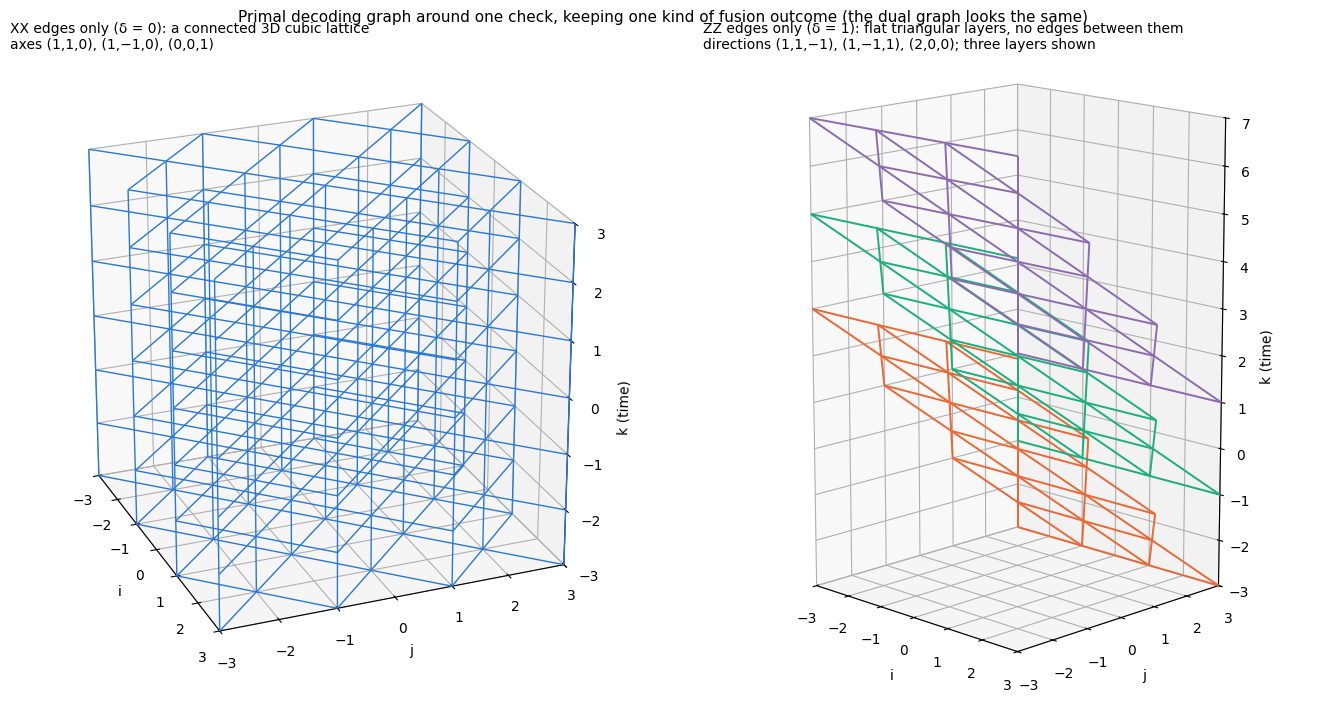

In [ ]:
import matplotlib.pyplot as plt
from collections import defaultdict, deque
from mpl_toolkits.mplot3d.art3d import Line3DCollection


def unwrapped_patch(net, ends, seed, radius, origin=(0, 0, 0)):
    """Walk the graph out from check `seed`, placing each check at its unwrapped offset from
    the seed (+ origin) and stopping at `radius` cells in any direction. Returns the line
    segments of every edge between two placed checks. With radius < L/2 this is a faithful
    local picture of the graph, with no periodic wrap-around."""
    adj = defaultdict(list)
    for a, b in ends:
        d = edge_offset(net, a, b)
        adj[a].append((b, d)); adj[b].append((a, -d))
    pos, queue = {seed: np.zeros(3, dtype=int)}, deque([seed])
    while queue:
        a = queue.popleft()
        for b, d in adj[a]:
            if b not in pos and np.abs(pos[a] + d).max() <= radius:
                pos[b] = pos[a] + d
                queue.append(b)
    return [[pos[a] + origin, pos[b] + origin] for a, b in ends
            if a in pos and b in pos and np.array_equal(pos[b] - pos[a], edge_offset(net, a, b))]


ends_xx = sector_edges(net8, ch8, is_xx8, "primal")
ends_zz = sector_edges(net8, ch8, ~is_xx8, "primal")
seed = net8._id[(0, 0, 0)]

fig = plt.figure(figsize=(14, 6.9))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.add_collection3d(Line3DCollection(unwrapped_patch(net8, ends_xx, seed, 3), colors="#2a78d6", linewidths=1.0))
ax.set_title("XX edges only (δ = 0): a connected 3D cubic lattice\n"
             "axes (1,1,0), (1,−1,0), (0,0,1)", fontsize=10, loc="left")

# three neighbouring ZZ layers: the layers are planes with normal (0,1,1), so the cells
# at k = 0, 2, 4 above the seed sit in three different (non-adjacent) layers
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
for dk, colour in zip((0, 2, 4), ("#eb6834", "#1baf7a", "#8c6bb1")):
    segs = unwrapped_patch(net8, ends_zz, net8._id[(0, 0, dk)], 3, origin=(0, 0, dk))
    ax2.add_collection3d(Line3DCollection(segs, colors=colour, linewidths=1.4))
ax2.set_title("ZZ edges only (δ = 1): flat triangular layers, no edges between them\n"
              "directions (1,1,−1), (1,−1,1), (2,0,0); three layers shown", fontsize=10, loc="left")

for a, top, view in ((ax, 3, (24, -22)), (ax2, 7, (14, -45))):
    a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.set_zlim(-3, top)
    a.set_box_aspect((6, 6, top + 3))
    for axis in (a.xaxis, a.yaxis, a.zaxis):
        axis.set_major_locator(plt.MaxNLocator(integer=True))
    a.set_xlabel("i"); a.set_ylabel("j"); a.set_zlabel("k (time)")
    a.view_init(*view)
fig.suptitle("Primal decoding graph around one check, keeping one kind of fusion outcome "
             "(the dual graph looks the same)", fontsize=11)
fig.tight_layout()
plt.show()

In [ ]:
import multiprocessing as mp
import time

BIAS_LS = [12, 16, 18]                                  # coarse pass uses the first two
BIAS_DELTAS = np.round(np.linspace(0, 1, 9), 4)
BIAS_COARSE_PS = np.round(np.geomspace(0.004, 0.08, 15), 6)
BIAS_FINE_SPAN = (0.75, 1.25, 11)                       # fine grid: centre x linspace(*)
SHOTS_BIAS, SEED_BIAS, BIAS_WORKERS = 20000, 2026, 4

_bias_cache = {}


def bias_split(p, delta):
    """(XX-outcome rate, ZZ-outcome rate) = (2 (1 - delta) p, 2 delta p): delta = 0.5
    puts p on both, which is §5's model."""
    return 2 * (1 - delta) * p, 2 * delta * p


def rows_to_parities_packed(outcomes, rows, _cache={}):
    """Same result as §7's rows_to_parities, but XORs 8 shots at a time by packing the
    shots axis into bits (as in Hexagon_fbqc_walkthrough.ipynb §6). Each row's column
    indices are cached, keyed on the rows array's id."""
    shots = outcomes.shape[0]
    packed = np.packbits(outcomes, axis=0)              # (ceil(shots/8), nmeas)
    key = id(rows)
    if key not in _cache:
        _cache[key] = [np.flatnonzero(rows[r]) for r in range(rows.shape[0])]
    out_packed = np.zeros((packed.shape[0], rows.shape[0]), dtype=np.uint8)
    for r, idx in enumerate(_cache[key]):
        out_packed[:, r] = np.bitwise_xor.reduce(packed[:, idx], axis=1)
    return np.unpackbits(out_packed, axis=0, count=shots)


_bias_pstate = {}


def _bias_decode_worker(dets_chunk):
    """Runs in a forked child; the reweighted Matching is inherited copy-on-write (§7)."""
    return _bias_pstate['matcher'].decode_batch(dets_chunk)


def decode_batch_parallel(matcher, dets, n_workers=BIAS_WORKERS):
    """matcher.decode_batch sharded across forked workers."""
    if n_workers <= 1 or dets.shape[0] < 4 * n_workers:
        return matcher.decode_batch(dets)
    _bias_pstate['matcher'] = matcher
    with mp.get_context("fork").Pool(n_workers) as pool:
        parts = pool.map(_bias_decode_worker, np.array_split(dets, n_workers, axis=0))
    return np.concatenate(parts, axis=0)


def bias_structure(L):
    """Checks, logicals, a private copy of §7's one-edge-per-outcome matcher (it gets
    reweighted, so it is not shared with §7's cache), the XX-outcome mask and one
    noiseless SHOTS_BIAS-shot sample. Nothing here depends on (p, delta)."""
    if L not in _bias_cache:
        t0 = time.time()
        n = Net(L)
        memory_circuit(L, n.Lk, 0.0)                    # fills §5's _cache
        ch, lg, nm = _cache[(L, n.Lk)]
        matcher, outcome_edge, _ = build_outcome_matching(n, ch, lg, 0.01)
        circ_, rec, nm2 = build(n, 0.0)
        assert nm2 == nm
        is_xx = np.zeros(nm, dtype=bool)
        is_xx[[ixx for ixx, _ in rec.values()]] = True  # §2: the 1st record is X_aX_b
        raw = circ_.compile_sampler(seed=SEED_BIAS, skip_reference_sample=True).sample(
            SHOTS_BIAS).astype(np.uint8)
        _bias_cache[L] = dict(checks=ch, logs=lg, nmeas=nm, matcher=matcher,
                              outcome_edge=outcome_edge, is_xx=is_xx, raw=raw, weights=None)
        print(f"  [bias structure L={L}: outcomes={nm} edges={matcher.num_edges} "
              f"({time.time() - t0:.0f}s)]", flush=True)
    return _bias_cache[L]


def reweight_bias(S, q_xx, q_zz):
    """Set every edge to log((1 - q)/q) for its outcome's flip rate q. q = 0 gets a large
    finite weight (pymatching drops edges above its cap, §7). MWPM only sees the ratio
    of the two weights, so this is skipped when the ratio is unchanged."""
    w = lambda q: float(np.log((1 - q) / q)) if q > 0 else 40.0
    w_xx, w_zz = w(q_xx), w(q_zz)
    key = round(w_xx / w_zz, 9)
    if S['weights'] == key:
        return
    for i, (u, v, fids) in S['outcome_edge'].items():
        S['matcher'].add_edge(u, v, weight=w_xx if S['is_xx'][i] else w_zz,
                              fault_ids=set(fids), merge_strategy="replace")
    S['weights'] = key


def bias_flip(S, q_xx, q_zz, rng, chunk=2000):
    """The noiseless sample with XX outcomes flipped at q_xx and ZZ outcomes at q_zz.
    Chunked: a (shots, nmeas) float array is several GB at L = 16."""
    q = np.where(S['is_xx'], q_xx, q_zz).astype(np.float32)
    outcomes = S['raw'].copy()
    for s0 in range(0, outcomes.shape[0], chunk):
        blk = outcomes[s0:s0 + chunk]
        blk ^= (rng.random(blk.shape, dtype=np.float32) < q).astype(np.uint8)
    return outcomes


def bias_meas_p_sweep(L, delta, ps, n_workers=BIAS_WORKERS):
    """Logical failure rate (any of the 6 observables) vs p_meas at fixed delta."""
    S = bias_structure(L)
    rates = []
    for p in ps:
        q_xx, q_zz = bias_split(p, delta)
        rng = np.random.default_rng((SEED_BIAS, L, int(round(p * 1e6)), int(round(delta * 1e4))))
        outcomes = bias_flip(S, q_xx, q_zz, rng)
        reweight_bias(S, q_xx, q_zz)
        dets = rows_to_parities_packed(outcomes, S['checks'])
        obs = rows_to_parities_packed(outcomes, S['logs'])
        pred = decode_batch_parallel(S['matcher'], dets, n_workers)
        rates.append(np.any(pred != obs, axis=1).sum() / outcomes.shape[0])
    return np.array(rates)


# --- checks -------------------------------------------------------------------------
# 1. the flips land where they should: at delta = 0.25, XX outcomes at 1.5p, ZZ at 0.5p
S = bias_structure(8)
flips = bias_flip(S, *bias_split(0.02, 0.25), np.random.default_rng(1)) ^ S['raw']
print(f"delta = 0.25, p = 2%: XX flip rate {flips[:, S['is_xx']].mean():.4f} (expect 0.0300), "
      f"ZZ flip rate {flips[:, ~S['is_xx']].mean():.4f} (expect 0.0100)")

# 2. at delta = 0.5 the reweighted matcher has uniform weights, so it must decode
#    exactly like §5's DEM-built matcher, up to ties between equal-weight matchings
reweight_bias(S, 0.01, 0.01)
m_dem = pymatching.Matching.from_detector_error_model(
    memory_circuit(8, None, 0.01).detector_error_model(decompose_errors=True))
d = rows_to_parities_packed(bias_flip(S, 0.012, 0.012, np.random.default_rng(3))[:2000], S['checks'])
n_diff = n_wdiff = 0
for s in range(d.shape[0]):
    a, wa = m_dem.decode(d[s], return_weight=True)
    b, wb = S['matcher'].decode(d[s], return_weight=True)
    n_diff += not np.array_equal(a, b)
    n_wdiff += not np.isclose(wa / m_dem.edges()[0][2]['weight'], wb / S['matcher'].edges()[0][2]['weight'])
print(f"uniform-weight bias matcher vs §5 matcher: predictions differ on {n_diff}/2000 shots, "
      f"matching weight (in edge units) differs on {n_wdiff}")
assert n_wdiff == 0

  [built L=8,Lk=8: outcomes=3072 checks=510 logicals=6]


  [bias structure L=8: outcomes=3072 edges=3072 (22s)]


delta = 0.25, p = 2%: XX flip rate 0.0300 (expect 0.0300), ZZ flip rate 0.0100 (expect 0.0100)


uniform-weight bias matcher vs §5 matcher: predictions differ on 0/2000 shots, matching weight (in edge units) differs on 0


In [ ]:
import json
import os

BIAS_DIR = "bias_threshold"
os.makedirs(BIAS_DIR, exist_ok=True)
COMPARE_LS = [8, 12, 16]                    # the earlier, smaller run, kept for comparison


def pairs_of(Ls):
    return [f"{a}x{b}" for a, b in zip(Ls[:-1], Ls[1:])]


def bias_paths(Ls):
    """(curves .jsonl, crossings .csv) for one set of sizes, e.g. ..._L12-16-18_curves.jsonl."""
    tag = "_L" + "-".join(map(str, Ls))
    return (os.path.join(BIAS_DIR, f"sixring_meas_threshold_vs_delta{tag}_curves.jsonl"),
            os.path.join(BIAS_DIR, f"sixring_meas_threshold_vs_delta{tag}.csv"))


PAIRS = pairs_of(BIAS_LS)


def two_pass_threshold(delta, Ls=BIAS_LS):
    """Coarse crossing of the two smallest sizes, then a fine grid around it at all sizes."""
    coarse = [bias_meas_p_sweep(L, delta, BIAS_COARSE_PS) for L in Ls[:2]]
    centre = find_crossing(BIAS_COARSE_PS, coarse[0], coarse[1])
    r = dict(delta=float(delta), Ls=list(Ls), centre=centre, coarse_ps=BIAS_COARSE_PS.tolist(),
             coarse=[c.tolist() for c in coarse], ps=None, curves=None,
             crossings=[None] * (len(Ls) - 1))
    if centre is not None:
        ps = np.round(centre * np.linspace(*BIAS_FINE_SPAN), 6)
        curves = [bias_meas_p_sweep(L, delta, ps) for L in Ls]
        r.update(ps=ps.tolist(), curves=[c.tolist() for c in curves],
                 crossings=[find_crossing(ps, curves[i], curves[i + 1]) for i in range(len(Ls) - 1)])
    return r


def run_threshold_vs_delta(Ls=BIAS_LS):
    """{delta: two_pass_threshold(delta, Ls)}, reloading any delta already in the curves file."""
    curves_path, csv_path = bias_paths(Ls)
    pairs = pairs_of(Ls)
    results = {}
    if os.path.exists(curves_path):
        with open(curves_path) as f:
            for line in f:
                r = json.loads(line)
                assert r['Ls'] == list(Ls), f"{curves_path} holds sizes {r['Ls']}, not {Ls}"
                results[r['delta']] = r
        print(f"loaded {len(results)} delta(s) from {curves_path}")
    t_all = time.time()
    for delta in BIAS_DELTAS:
        if float(delta) in results:
            continue
        t0 = time.time()
        results[float(delta)] = r = two_pass_threshold(delta, Ls)
        with open(curves_path, "a") as f:
            f.write(json.dumps(r) + "\n")
        cells_ = "  ".join(f"{(f'{x * 100:.3f}%' if x is not None else '--'):>8}" for x in r['crossings'])
        centre = f"{r['centre'] * 100:.2f}%" if r['centre'] else "none"
        print(f"  δ={delta:.3f}: coarse centre {centre}   {', '.join(pairs)}: {cells_}   "
              f"({time.time() - t0:.0f}s)", flush=True)
    print(f"sampling time this run: {time.time() - t_all:.0f}s")
    with open(csv_path, "w") as f:
        f.write("delta,coarse_centre," + ",".join(f"cross_{p}" for p in pairs) + "\n")
        for d in sorted(results):
            r = results[d]
            f.write(f"{d}," + ",".join("" if x is None else f"{x:.6g}"
                                       for x in [r['centre']] + list(r['crossings'])) + "\n")
    print(f"saved {csv_path}")
    return dict(sorted(results.items()))


th_vs_delta = run_threshold_vs_delta(BIAS_LS)
th_vs_delta_cmp = run_threshold_vs_delta(COMPARE_LS)

  [built L=12,Lk=12: outcomes=10368 checks=1726 logicals=6]


  [bias structure L=12: outcomes=10368 edges=10368 (77s)]


  [built L=16,Lk=16: outcomes=24576 checks=4094 logicals=6]


  [bias structure L=16: outcomes=24576 edges=24576 (180s)]


  [built L=18,Lk=18: outcomes=34992 checks=5830 logicals=6]


...

  δ=0.625: coarse centre 1.07%   12x16, 16x18:   1.103%    1.069%   (707s)


  δ=0.750: coarse centre 1.17%   12x16, 16x18:   1.172%    1.167%   (611s)


  δ=0.875: coarse centre 1.34%   12x16, 16x18:   1.368%    1.304%   (599s)


  δ=1.000: coarse centre 2.55%   12x16, 16x18:   2.473%    2.623%   (522s)


sampling time this run: 100390s
saved bias_threshold/sixring_meas_threshold_vs_delta_L12-16-18.csv
loaded 9 delta(s) from bias_threshold/sixring_meas_threshold_vs_delta_L8-12-16_curves.jsonl
sampling time this run: 0s
saved bias_threshold/sixring_meas_threshold_vs_delta_L8-12-16.csv


δ = 0.000: p_c = 0.01464 ± 0.00003 (abs. sigma), ± 0.00005 (scaled by sqrt(chi2/dof))   nu = 1.033 ± 0.016   chi2/dof = 2.28 (33 points, 3 sizes)


δ = 0.125: p_c = 0.01247 ± 0.00003 (abs. sigma), ± 0.00004 (scaled by sqrt(chi2/dof))   nu = 1.063 ± 0.019   chi2/dof = 1.77 (33 points, 3 sizes)
δ = 0.250: p_c = 0.01143 ± 0.00003 (abs. sigma), ± 0.00004 (scaled by sqrt(chi2/dof))   nu = 1.033 ± 0.018   chi2/dof = 2.41 (33 points, 3 sizes)
δ = 0.375: p_c = 0.01099 ± 0.00003 (abs. sigma), ± 0.00003 (scaled by sqrt(chi2/dof))   nu = 1.003 ± 0.018   chi2/dof = 1.02 (33 points, 3 sizes)
δ = 0.500: p_c = 0.01068 ± 0.00003 (abs. sigma), ± 0.00003 (scaled by sqrt(chi2/dof))   nu = 1.016 ± 0.018   chi2/dof = 1.01 (33 points, 3 sizes)
δ = 0.625: p_c = 0.01099 ± 0.00003 (abs. sigma), ± 0.00004 (scaled by sqrt(chi2/dof))   nu = 1.023 ± 0.019   chi2/dof = 1.67 (33 points, 3 sizes)
δ = 0.750: p_c = 0.01170 ± 0.00003 (abs. sigma), ± 0.00004 (scaled by sqrt(chi2/dof))   nu = 1.026 ± 0.018   chi2/dof = 1.35 (33 points, 3 sizes)
δ = 0.875: p_c = 0.01341 ± 0.00004 (abs. sigma), ± 0.00005 (scaled by sqrt(chi2/dof))   nu = 1.088 ± 0.022   chi2/dof = 1.49

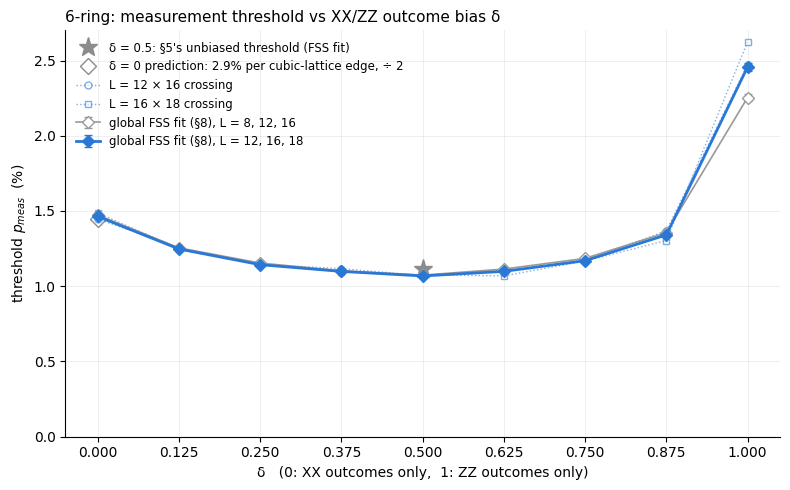


δ = 1, every crossing (sizes increasing left to right):   8x12: 2.163%   12x16: 2.418%   12x16: 2.473%   16x18: 2.623%


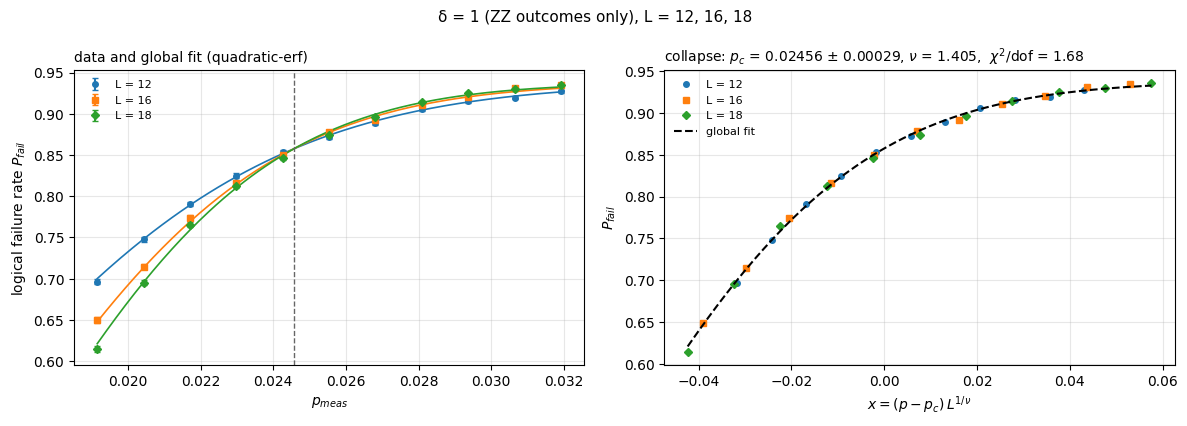

δ = 1 (ZZ outcomes only), L = 12, 16, 18: p_c = 0.02456 ± 0.00022 (abs. sigma), ± 0.00029 (scaled by sqrt(chi2/dof))   nu = 1.405 ± 0.089   chi2/dof = 1.68 (33 points, 3 sizes)


In [ ]:
import matplotlib.pyplot as plt

P_C_SEC5 = 0.01116          # §5's global FSS threshold (δ = 0.5)
P_TH_CUBIC = 0.029          # MWPM threshold per edge on the cubic lattice (Wang-Harrington-Preskill)

fmt = lambda x: f"{x * 100:.3f}%" if x is not None else "--"


def fss_vs_delta(th, Ls, verbose=True):
    """§8's global FSS fit on each δ's fine-grid curves. At δ = 1 only 4 of the 6
    observables can fail, so the curves saturate at 15/16, not 1."""
    out = {}
    for d, r in th.items():
        if r['curves'] is None:
            continue
        out[d] = fss_threshold({L: (r['ps'], c) for L, c in zip(Ls, r['curves'])}, SHOTS_BIAS,
                               p_max=15 / 16 if d == 1.0 else 1.0, plot=False, title=f"δ = {d:.3f}")
    if verbose:
        print(f"\nL = {', '.join(map(str, Ls))}")
        print(f"{'δ':>6} | " + " ".join(f"{p:>8}" for p in pairs_of(Ls))
              + f" | {'FSS p_c':>8} {'± (scaled)':>10} {'nu':>6} {'chi2/dof':>8}")
        for d, f_ in out.items():
            print(f"{d:>6.3f} | " + " ".join(f"{fmt(x):>8}" for x in th[d]['crossings'])
                  + f" | {f_['p_c'] * 100:>7.3f}% {f_['p_c_err_scaled'] * 100:>9.3f}% {f_['nu']:>6.2f} "
                  f"{f_['chi2_dof']:>8.2f}")
    return out


fss_by_delta = fss_vs_delta(th_vs_delta, BIAS_LS)
fss_by_delta_cmp = fss_vs_delta(th_vs_delta_cmp, COMPARE_LS)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([0.5], [P_C_SEC5 * 100], marker="*", ms=14, color="0.55", ls="none",
        label="δ = 0.5: §5's unbiased threshold (FSS fit)")
ax.plot([0.0], [P_TH_CUBIC / 2 * 100], marker="D", ms=8, color="0.55", ls="none", mfc="white",
        label="δ = 0 prediction: 2.9% per cubic-lattice edge, ÷ 2")
for k, (mk, pair) in enumerate(zip(("o", "s"), PAIRS)):
    pts = [(d, r['crossings'][k]) for d, r in th_vs_delta.items() if r['crossings'][k] is not None]
    ax.plot([d for d, _ in pts], [x * 100 for _, x in pts], marker=mk, ms=5, lw=1, ls=":",
            color="#2a78d6", mfc="white", alpha=0.6, label=f"L = {pair.replace('x', ' × ')} crossing")
for fss, Ls, col, lw, mfc in ((fss_by_delta_cmp, COMPARE_LS, "0.6", 1.2, "white"),
                              (fss_by_delta, BIAS_LS, "#2a78d6", 2.0, None)):
    ds = list(fss)
    ax.errorbar(ds, [fss[d]['p_c'] * 100 for d in ds], yerr=[fss[d]['p_c_err_scaled'] * 100 for d in ds],
                fmt="D-", ms=6, lw=lw, capsize=3, color=col, mfc=mfc or col,
                label=f"global FSS fit (§8), L = {', '.join(map(str, Ls))}")
ax.set_xlabel("δ   (0: XX outcomes only,  1: ZZ outcomes only)")
ax.set_ylabel("threshold $p_{meas}$  (%)")
ax.set_xticks(np.linspace(0, 1, 9))
ax.set_ylim(bottom=0)
ax.grid(alpha=.25, lw=.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(fontsize=8.5, frameon=False, loc="upper left")
ax.set_title("6-ring: measurement threshold vs XX/ZZ outcome bias δ", fontsize=11, loc="left")
fig.tight_layout()
fig.savefig(bias_paths(BIAS_LS)[1].replace(".csv", ".png"), dpi=150)
plt.show()

print("\nδ = 1, every crossing (sizes increasing left to right):   " + "   ".join(
    f"{p}: {fmt(x)}" for th, Ls in ((th_vs_delta_cmp, COMPARE_LS), (th_vs_delta, BIAS_LS))
    for p, x in zip(pairs_of(Ls), th[1.0]['crossings'])))
r1 = th_vs_delta[1.0]
_ = fss_threshold({L: (r1['ps'], c) for L, c in zip(BIAS_LS, r1['curves'])}, SHOTS_BIAS, p_max=15 / 16,
                  title=f"δ = 1 (ZZ outcomes only), L = {', '.join(map(str, BIAS_LS))}", xlabel="$p_{meas}$")

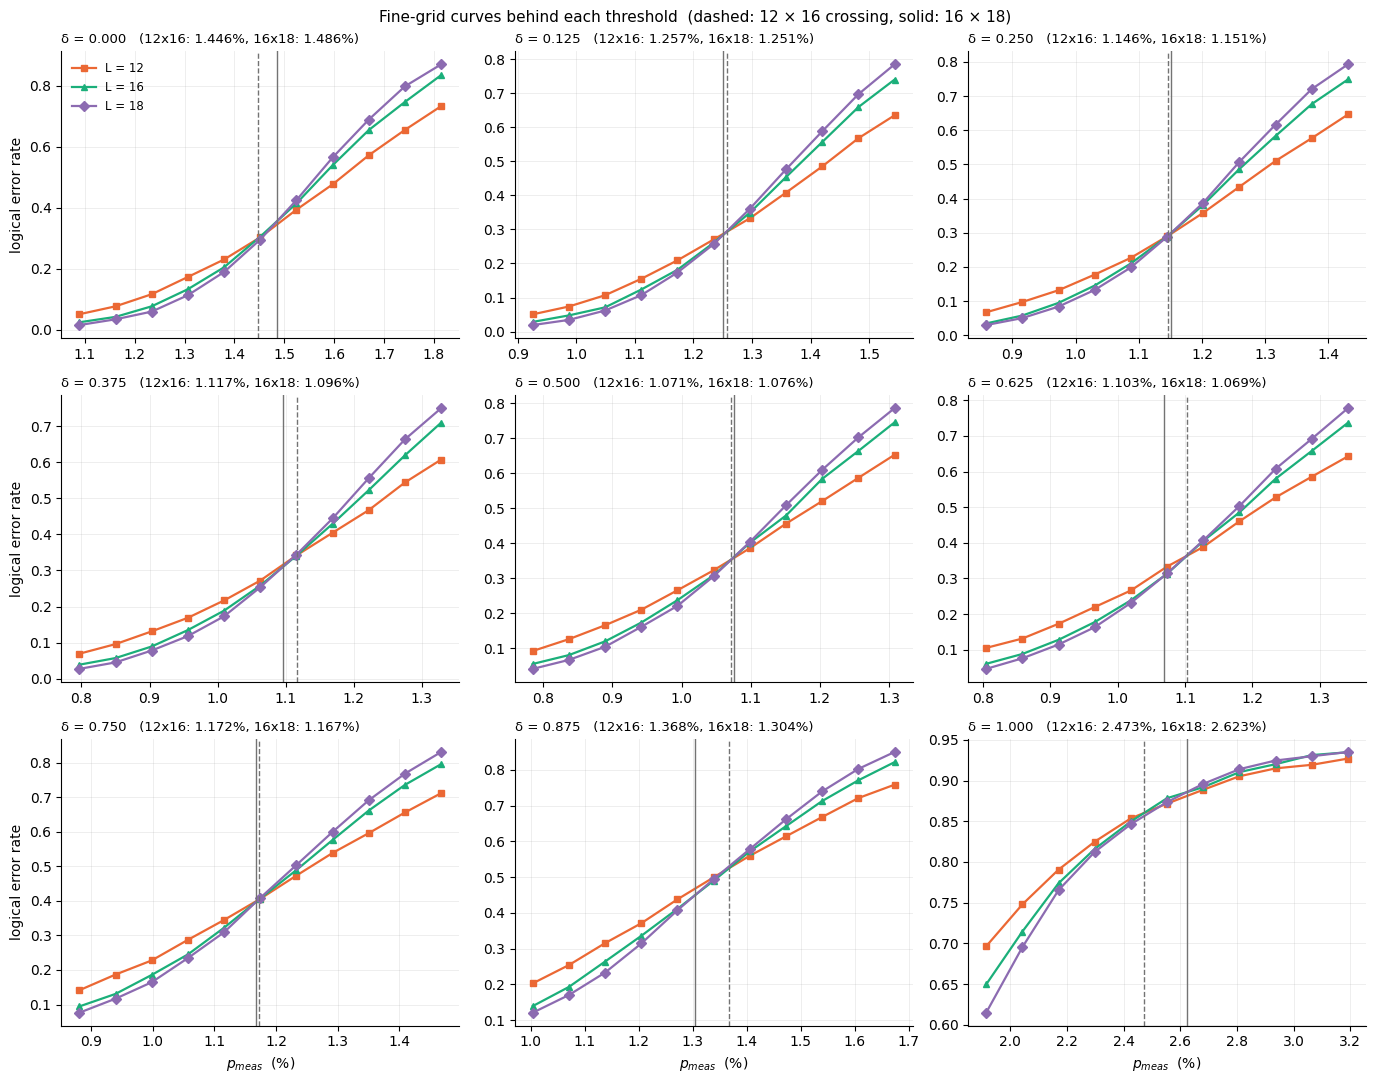

In [ ]:
BIAS_SIZE_STYLE = {8: ("#2a78d6", "o"), 12: ("#eb6834", "s"), 16: ("#1baf7a", "^"),
                   18: ("#8c6bb1", "D")}                                  # fixed per L


def plot_delta_curves(th, Ls, save=None):
    """One panel per δ: the fine-grid curves behind each crossing (coarse ones if there was none)."""
    pairs = pairs_of(Ls)
    fig, axes = plt.subplots(3, 3, figsize=(14, 11))
    for ax, (d, r) in zip(axes.ravel(), th.items()):
        fine = r['curves'] is not None
        ps, curves = (r['ps'], r['curves']) if fine else (r['coarse_ps'], r['coarse'])
        for L, curve in zip(Ls, curves):
            col, mk = BIAS_SIZE_STYLE[L]
            ax.plot(np.array(ps) * 100, curve, color=col, marker=mk, ms=5, lw=1.6, label=f"L = {L}")
        for k, x in enumerate(r['crossings']):
            if x is not None:
                ax.axvline(x * 100, color="0.45", lw=1, ls="--" if k == 0 else "-")
        lab = ", ".join(f"{p}: {fmt(x)}" for p, x in zip(pairs, r['crossings']))
        ax.set_title(f"δ = {d:.3f}   ({lab})" if fine else
                     f"δ = {d:.3f}  (coarse only: no {pairs[0].replace('x', ' × ')} crossing)",
                     fontsize=9.5, loc="left")
        ax.grid(alpha=.25, lw=.6)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("$p_{meas}$  (%)")
    for ax in axes[:, 0]:
        ax.set_ylabel("logical error rate")
    axes[0, 0].legend(fontsize=8.5, frameon=False, loc="upper left")
    fig.suptitle(f"Fine-grid curves behind each threshold  (dashed: {pairs[0].replace('x', ' × ')} "
                 f"crossing, solid: {pairs[1].replace('x', ' × ')})", fontsize=11)
    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=150)
    plt.show()


plot_delta_curves(th_vs_delta, BIAS_LS, save=bias_paths(BIAS_LS)[0].replace(".jsonl", ".png"))

### Result

Threshold from §8's global fit (scaled errors ±0.003-0.005 points for `δ < 1`):

| `δ` | `L = 12, 16, 18` | `ν` | `L = 8, 12, 16` | crossings 12 x 16 / 16 x 18 |
|---|---|---|---|---|
| 0 (`XX` only) | **1.464%** | 1.03 | 1.473% | 1.45% / 1.49% |
| 0.125 | **1.247%** | 1.06 | 1.255% | 1.26% / 1.25% |
| 0.25  | **1.143%** | 1.03 | 1.154% | 1.15% / 1.15% |
| 0.375 | **1.099%** | 1.00 | 1.103% | 1.12% / 1.10% |
| 0.5   | **1.068%** | 1.02 | 1.074% | 1.07% / 1.08% |
| 0.625 | **1.099%** | 1.02 | 1.114% | 1.10% / 1.07% |
| 0.75  | **1.170%** | 1.03 | 1.185% | 1.17% / 1.17% |
| 0.875 | **1.341%** | 1.09 | 1.356% | 1.37% / 1.30% |
| 1 (`ZZ` only) | ≥ 2.46%, not converged | 1.40 | 2.25% | 2.47% / 2.62% |

* **Converged for every `δ < 1`.** The larger sizes move each threshold by at most
  0.015 points. The fits are good (chi2/dof 1.0-2.4) and agree with the crossings.
* **Both predictions hold.** `δ = 0.5` gives 1.068%, matching the paper's 1.07%. (§5's
  1.116% comes from a fit with chi2/dof ≈ 9 that includes `L = 4`; see §8.) `δ = 0`
  gives 1.464%, i.e. 2.93% per edge, which is the 2.9% cubic-lattice prediction.
* **Unbiased noise is the worst case.** The threshold is lowest at `δ = 0.5` and rises
  on both sides, so moving the noise onto either outcome type helps.
* **The curve is not symmetric about `δ = 0.5`.** Near the middle it is: `δ = 0.375`
  and `0.625` both give 1.099%. Further out, the `ZZ`-heavy side is higher: 1.170%
  vs 1.143% at distance 0.25 from the middle, and 1.341% vs 1.247% at distance
  0.375. At `δ = 1` it jumps to at least 2.46%, against 1.46% at `δ = 0`.
* **`δ = 1` still does not converge.** Its crossings keep rising with size: 2.16%
  (8 x 12), 2.42-2.47% (12 x 16), then 2.62% (16 x 18). The curves cross at failure
  rates around 0.85, close to their 15/16 saturation, where they are nearly flat. So
  2.46% is a lower bound. `ν` there is 1.40, against 1.0-1.09 everywhere else. The
  next subsection explains why this end is different.

### Why `ZZ` noise is tolerated better, and why the curve is lopsided

The cause is the geometry of the decoding graph (the 3D picture above), not the noise
itself:

* **`XX`-outcome errors live on a connected 3D cubic lattice.** That is the
  phenomenological toric-code matching problem, with a threshold of about 2.9% per
  edge.
* **`ZZ`-outcome errors live only on flat 2D triangular layers,** with no edges between
  layers. A 2D matching problem has no third direction for error strings to spread
  along, so it tolerates a much higher flip rate per edge. For comparison, the square
  lattice's 2D MWPM threshold is 10.3%, against 2.9% for the 3D cubic lattice.

The picture below shows this in terms of per-edge flip rates. Each `δ`'s threshold is
drawn as the point `(q_XX, q_ZZ) = (2 (1 - δ) p_th, 2 δ p_th)`, the flip rate of each
`XX` edge and each `ZZ` edge at threshold. Noise inside the curve is correctable. The
dashed line is the same curve mirrored (`XX` ↔ `ZZ`). If the two edge types were
interchangeable, the curve would sit on its own mirror image.

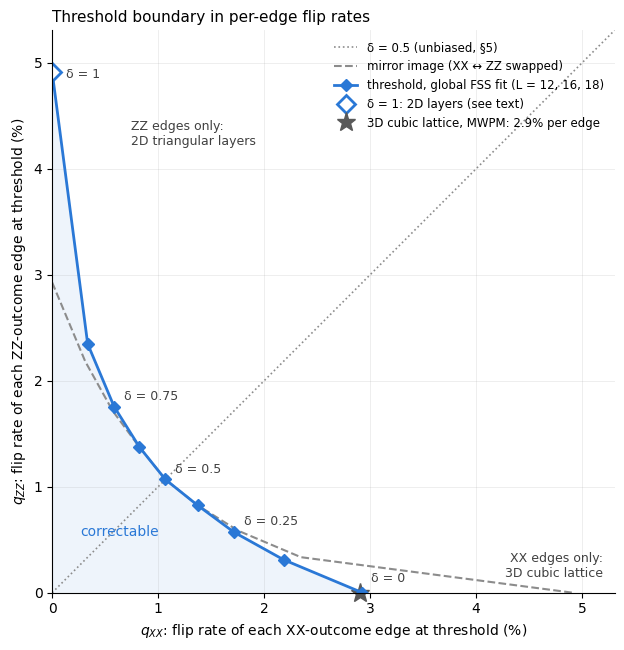

In [ ]:
# Each δ's threshold as a point in the plane of per-edge flip rates at threshold,
# (q_XX, q_ZZ) = (2 (1 - δ) p_th, 2 δ p_th). Inside the curve is correctable.
ds = np.array(list(fss_by_delta))
pc = np.array([fss_by_delta[d]['p_c'] for d in ds]) * 100
q_xx, q_zz = 2 * (1 - ds) * pc, 2 * ds * pc
top = 1.08 * max(q_xx.max(), q_zz.max())

fig, ax = plt.subplots(figsize=(7, 6.6))
ax.fill(np.r_[0, q_xx, 0], np.r_[0, q_zz, 0], color="#2a78d6", alpha=0.08, lw=0)
ax.plot([0, top], [0, top], ":", color="0.55", lw=1.2, label="δ = 0.5 (unbiased, §5)")
ax.plot(q_zz, q_xx, "--", color="0.55", lw=1.5, label="mirror image (XX ↔ ZZ swapped)")
ax.plot(q_xx, q_zz, "D-", color="#2a78d6", ms=6, lw=2,
        label=f"threshold, global FSS fit (L = {', '.join(map(str, BIAS_LS))})")
ax.plot(q_xx[ds == 1], q_zz[ds == 1], "D", ms=9, color="#2a78d6", mfc="white", mew=2,
        label="δ = 1: 2D layers (see text)")
ax.plot([P_TH_CUBIC * 100], [0], "*", ms=14, color="0.35", clip_on=False, zorder=1,
        label="3D cubic lattice, MWPM: 2.9% per edge")
for d, x, z in zip(ds, q_xx, q_zz):
    if d in (0.0, 0.25, 0.5, 0.75, 1.0):
        ax.annotate(f"δ = {d:g}", (x, z), textcoords="offset points", fontsize=9, color="0.25",
                    xytext={0.0: (6, 8), 1.0: (10, -4)}.get(d, (7, 5)))
ax.text(0.98 * top, 0.12, "XX edges only:\n3D cubic lattice", ha="right", va="bottom", fontsize=9, color="0.25")
ax.text(0.14 * top, 0.84 * top, "ZZ edges only:\n2D triangular layers", ha="left", va="top", fontsize=9, color="0.25")
ax.text(0.12 * top, 0.1 * top, "correctable", fontsize=10, color="#2a78d6", ha="center")
ax.set_xlim(0, top); ax.set_ylim(0, top); ax.set_aspect("equal")
ax.set_xlabel("$q_{XX}$: flip rate of each XX-outcome edge at threshold (%)")
ax.set_ylabel("$q_{ZZ}$: flip rate of each ZZ-outcome edge at threshold (%)")
ax.grid(alpha=.25, lw=.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(fontsize=8.5, frameon=False, loc="upper right")
ax.set_title("Threshold boundary in per-edge flip rates", fontsize=11, loc="left")
fig.tight_layout()
fig.savefig(bias_paths(BIAS_LS)[1].replace(".csv", "_boundary.png"), dpi=150)
plt.show()

* **The middle is symmetric.** From about `δ = 0.25` to `0.75` the curve follows its
  mirror image. With both edge types present, the graph is §5's connected 3D,
  degree-12 graph, and it hardly matters which edges carry slightly more of the noise.
* **The ends are not.** The `XX`-only end stops at 2.93% per edge, on the 3D
  cubic-lattice value (star). The `ZZ`-only end reaches at least 4.9% per edge, and it
  is still rising with `L`, because that problem is 2D.
* **Why the two ends approach differently.** Near `δ = 1`, a few `XX` errors act as
  rare links between otherwise separate 2D layers. The problem is "almost 2D", so the
  threshold starts high and falls quickly as `XX` noise is added (from at least 2.46%
  at `δ = 1` to 1.34% at `0.875`). Near `δ = 0`, a few `ZZ` errors only add extra
  diagonal links to a lattice that is already 3D. Nothing qualitative changes, so the
  threshold falls smoothly from 1.46%.
* **This also explains the poor convergence at `δ = 1`.** A layered problem has two
  length scales: the size of each 2D layer, and the number of layers (`L`, each of
  which can fail independently). Corrections to scaling are therefore larger, and
  `ν ≈ 1.4` there is closer to 2D values than to the ≈ 1.0 seen elsewhere.
* **Contrast with the hexagon code.** There, both edge types form 3D graphs, and its
  two ends come out about equal (1.48% / 1.49%, its §14b).

---
## Where to go next

1. **Match the boundary types** at top and bottom so a timelike membrane
   survives, then re-run §6 and look for high-weight elements in the sieved
   spectrum — those are your logicals.
2. **Qubit reuse.** Two 12-qubit blocks per cell alternating on `k % 2`; `M`
   then `R` already returns them clean, so no SWAPs. Do the downward fusion for
   layer `k` *before* re-prepping the block layer `k-2` used. Validate by
   checking the DEM still builds and the check ranks match this notebook's.
3. ~~**Erasure.**~~ Done — see §7. Heralded erasure with weight-0 edges via a
   hand-built, per-shot reweighted MWPM graph (not `from_detector_error_model`,
   which can't be reweighted per shot). Validated exact at L≥6; known narrow
   optimality gap at L=4 from small-lattice duplicate check-pairs (documented
   in §7, doesn't affect the target L≥10 regime).
4. **Bigger `L`** for a properly fitted threshold; the paper fits the CDF of a
   rescaled beta distribution across `L = 12, 16, 20`. §7's structure-build
   timing probe is relevant here too — it's shared with this item's `L` sweep.